[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/05_Malware_Detection/QMLP_QCNN_MalwareClassification_Lopez2025.ipynb)

# QMLP and QCNN for malware classification: Lopez, Nowmi, Cadena and Rahman (2025) step by step

> Jesus Lopez, Saeefa Rubaiyet Nowmi, Viviana Cadena and Mohammad Saidur Rahman, "Towards Quantum Machine Learning for Malicious Code Analysis",
> Department of Computer Science, University of Texas at El Paso, 2025. arXiv:2508.19381, https://arxiv.org/abs/2508.19381

**What this notebook does.** The paper trains two hybrid quantum-classical networks, a *Quantum Multilayer Perceptron* (QMLP) and a *Quantum Convolutional Neural Network* (QCNN), on five
malware benchmarks (API-Graph, EMBER-Domain, EMBER-Class, AZ-Domain, AZ-Class). Both circuits have **16 qubits**, one qubit per principal component of the malware feature vector. The EMBER
benchmark is public, so this notebook downloads the real **EMBER-2018** feature vectors (2 381 static features of Windows PE files, mirrored on Hugging Face), rebuilds the paper's pipeline
(min-max scaling, PCA to 16 components, angle embedding, the two 16-qubit circuits, a classical linear layer with log-softmax, Adam) and runs the paper's two EMBER experiments:
**EMBER-Domain** (binary benign/malware, trained on the first three months of 2018, evaluated on the rest of 2018) and **EMBER-Class** (top 4, 14 and 23 malware families).
Classical baselines (random forest, SVM, logistic regression) are trained on **exactly the same 16 PCA inputs** and on all 2 381 raw features. The notebook ends with the paper's numbers next to ours
and a verdict per claim. The API-Graph and AZ (AndroZoo) experiments cannot be rerun here, see the notes below.

**How to run it.** Open it in Google Colab, choose a **CPU** runtime and use *Runtime > Run all*. `FAST_MODE = True` is a class demo (about 10 minutes); `FAST_MODE = False` uses more data, more epochs and
two seeds (the budgets are in the configuration cell). No GPU and no IBM token are needed. The EMBER mirror is public; if you ever point `HF_REPO` at a gated mirror, store your own Hugging Face token as
the Colab secret `HF_TOKEN` (or the environment variable `HF_TOKEN` locally).

**What you get at the end.** The dataset exploration (real samples coloured by their true label), the drawings of the two 16-qubit PennyLane circuits, an exactness check of the fast simulator used for
training against the real PennyLane circuits (expectation values **and** gradients), trained models with confusion matrices, a table comparing paper and notebook, and a critical reading of the paper.

## The paper in one page

**Problem.** Static malware classification. Classical machine learning is well studied for it; the authors ask whether small *hybrid quantum-classical* networks can do the job.

**Decision.** Binary (benign vs malware: API-Graph, AZ-Domain, EMBER-Domain) and multiclass (malware family: API-Graph, AZ-Class, EMBER-Class with the **top 4, 14 and 23 families**).

**Method (Section II).** Both models are PennyLane circuits on **16 qubits**, simulated with `default.qubit` and trained end-to-end in PyTorch (`TorchLayer`), followed by a classical linear layer and `log_softmax`.
* **QMLP.** `RX(x_i)` angle embedding of the 16 inputs, a trainable `Rot(theta, phi, lambda)` on every qubit, a ring of trainable `CRX` gates, and then the **whole block repeated once more with new parameters**
  (data re-uploading). All 16 Pauli-Z expectation values go to `Linear(16, n_classes)`.
* **QCNN.** Angle embedding with `RX`, `RY`, `RZ` rotations, a "convolution" layer (`Rot` on every qubit + ring of trainable `CRX`), a first "pooling" that keeps the **even qubits** (0, 2, ..., 14),
  another `Rot` + `CRX` ring on the 8 survivors, a second pooling that keeps 4 qubits (0, 4, 8, 12); their Pauli-Z expectation values go to `Linear(4, n_classes)`.
* **Data.** Min-max scaling to [0, 1], then **PCA to 16 components**. EMBER-Domain: train on the first three months of 2018 (141 817 samples), evaluate on the rest of 2018 (75 006 samples).
  EMBER-Class: top 4 / 14 / 23 families (89 281 / 184 700 / 220 412 training samples, 9 930 / 20 464 / 24 445 test samples).
* **Training.** Adam, **20 epochs, batch 64**, three repetitions per experiment, noise-free `default.qubit`.

**Claims with numbers.**
* EMBER-Domain (Table II): QMLP accuracy **77.4 +- 2.5**, F1 77.3, ROC-AUC 83.0; QCNN accuracy **77.5 +- 0.2**, F1 77.4, ROC-AUC 84.1.
* EMBER-Class (Table I): QMLP accuracy **88.1 / 83.9 / 79.8** and QCNN **85.8 / 72.7 / 60.7** for 4 / 14 / 23 families (F1 86.2 / 83.0 / 76.6 and 83.7 / 68.4 / 48.1).
* Other datasets (not rerun here): API-Graph binary 96.3 / 96.0, AZ-Domain 91.2 / 91.3, multiclass API-Graph 95.7 to 91.6, AZ-Class QMLP 93.6 / 67.5 / 57.8 and QCNN 92.1 / 55.3 / 41.7.
* Qualitative: QMLP beats QCNN in the harder multiclass settings; QCNN trains faster but is less accurate; accuracy falls as the number of classes grows.

**Not stated in the paper:** learning rate, the exact CRX wiring after pooling, how the multiclass train/test split of EMBER-Class was drawn, the family naming (EMBER's `avclass`), weight initialisation,
the PyTorch/PennyLane versions and which statistic the +- values report.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Datasets | API-Graph, EMBER-Domain, EMBER-Class, AZ-Domain, AZ-Class | **EMBER-Domain and EMBER-Class only.** API-Graph (Zhang et al., CCS 2020) and AZ (AndroZoo, Chen et al.) are shared on request / behind an AndroZoo API key and no public mirror exists, so those claims are "cannot be checked" and nothing was substituted |
| EMBER data | EMBER 2018 (2 381 features), 141 817 + 75 006 samples for the binary task | the same EMBER-2018 vectors from the public Hugging Face mirror `cw1521/ember2018-malware`; **a few thousand samples** (first 300 lines of 24 + 24 evenly spaced chunks, see the configuration cell) instead of 217 k, because a 16-qubit circuit has to be simulated for every sample |
| Binary split | train: first three months of 2018, test: the rest of 2018 | same rule applied with the `appeared` month of each sample (train 2018-01 to 2018-03, test 2018-04 to 2018-12); training samples drawn at random from period A, test samples from period B |
| Multiclass split | top 4 / 14 / 23 families, about 90 % / 10 % | top-k malware families by count in our pool (family = EMBER's `avclass`, samples without a family excluded), stratified 70 / 30 split (CHOICE: the pool is small), then a capped subsample of the training part |
| Preprocessing | Min-Max to [0, 1], PCA to 16 | the same, fitted on the training split only; `# CHOICE:` the PCA outputs are used as rotation angles after an optional min-max rescaling to [0, pi] (decided on a validation split, see section 4) |
| QMLP circuit | 16 qubits, RX embedding, Rot, CRX ring, repeated twice, 16 Pauli-Z outputs | exactly this; `# CHOICE:` `CRX(q -> q+1 mod 16)` in qubit order, Rot as PennyLane's `Rot(phi, theta, omega)` |
| QCNN circuit | RX/RY/RZ embedding, conv (Rot + CRX ring), pool to 8, Rot + CRX, pool to 4, measure 4 | exactly this; `# CHOICE:` CRX ring on the 8 survivors in qubit order (0->2->...->14->0), the 4 final qubits are 0, 4, 8, 12 as the paper's example |
| Classical head | linear layer + log-softmax | `torch.nn.Linear` + `LogSoftmax`, `NLLLoss` |
| Optimiser | Adam (also "stochastic gradient descent") | Adam, `# CHOICE:` learning rate chosen on a validation split of the training data |
| Epochs / batch | 20 / 64 | FAST: 5 epochs, batch 32; full run: see the configuration cell (`# CHOICE:` budgets limited by simulation time) |
| Initial weights | not stated | `# CHOICE:` PennyLane `TorchLayer` default, uniform on [0, 2 pi) |
| Repetitions | 3 | FAST: 1 seed; full run: 2 seeds |
| Simulator | PennyLane `default.qubit`, noise-free | the circuits are drawn and verified with PennyLane `default.qubit`; for **training** an exact matrix-product-state (tensor-network) simulator written in PyTorch is used, because a per-sample 2^16 state-vector simulation takes minutes per epoch on a CPU. The notebook asserts that it returns the same expectation values and gradients as the real PennyLane QNodes (error about 1e-6) |
| Classical baselines | none in the paper | `RandomForest`, `SVC(rbf)`, logistic regression on the same 16 PCA inputs, and a random forest on all 2 381 features |

In [1]:
# ---- install (Colab only unless a package is missing locally) ----
import sys, importlib.util
IN_COLAB = "google.colab" in sys.modules
_need = [m for m in ("pennylane", "torch", "sklearn", "pandas", "matplotlib", "requests") if importlib.util.find_spec(m) is None]
if IN_COLAB or _need:
    # Pinned to the versions this notebook was tested with. Colab already ships numpy, pandas, scikit-learn, matplotlib and torch.
    !pip -q install "pennylane==0.45.1" "requests" "scikit-learn>=1.4" "pandas>=2.0"
    # A session restart may be required after the first install in Colab (Runtime -> Restart session), then Run all again.

**Hugging Face token.** The EMBER mirror used here is public, so no token is needed. If you point `HF_REPO` at a gated mirror, store your own token as the Colab *Secret* `HF_TOKEN`
(or the environment variable `HF_TOKEN` locally). The next cell reads it from there and nowhere else; it is never printed or written to a file.

In [2]:
import os
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
print("Hugging Face token available:", bool(HF_TOKEN), "(optional for the public mirror)")

Hugging Face token available: True (optional for the public mirror)


In [3]:
# ---- configuration: every tunable constant lives here ----
SEED = 42
FAST_MODE = False                   # True: ~10 minute class demo; False: larger samples, more epochs, 2 seeds (about 1 hour on a CPU)
IBM_TOKEN = ""                     # unused: the paper only needs a noise-free simulator (kept for template uniformity)
DATA_DIR = "qc229_data"            # cache of the downloaded EMBER chunks (kept out of the repository)
N_QUBITS = 16                      # paper: 16 qubits = 16 PCA components
CLASS_SIZES = [4, 14, 23]          # paper: top 4 / 14 / 23 malware families
LINES_PER_FILE = 300               # CHOICE: first 300 lines of each 2000-line EMBER chunk (cache key; the same cache serves FAST and full runs)
FILES_PER_PERIOD_FULL = 24         # CHOICE: 24 evenly spaced chunks per period (A = 2018-01..03, B = 2018-04..12)
N_DOWNLOAD_THREADS = 4
N_TORCH_THREADS = 1                # the tensors of the simulator are tiny: one thread is fastest

if FAST_MODE:
    FILE_STRIDE = 2                # every second chunk -> 12 chunks per period
    SEEDS = [0]                    # paper: 3 repetitions
    N_TRAIN_D, N_TEST_D = 300, 1000    # EMBER-Domain: training / evaluation samples (paper: 141 817 / 75 006)
    N_TRAIN_C, N_TEST_C = 300, 600     # EMBER-Class: training / evaluation samples (paper: 89 281 to 220 412 / 9 930 to 24 445)
    EPOCHS, BATCH = 5, 32          # paper: 20 epochs, batch 64
    TUNE_EPOCHS = 3
else:
    FILE_STRIDE = 1                # all 24 chunks per period
    SEEDS = [0, 1]
    N_TRAIN_D, N_TEST_D = 1000, 2000
    N_TRAIN_C, N_TEST_C = 1000, 800
    EPOCHS, BATCH = 12, 32
    TUNE_EPOCHS = 4

TUNE_LR_GRID = [0.01, 0.05, 0.1]        # CHOICE: Adam learning rate (not in the paper), picked on a validation split of the training data
TUNE_ANGLE_GRID = ["paper", "pi"]  # "paper": PCA outputs used directly as angles; "pi": min-max rescaled to [0, pi] (fitted on the training split)
N_TUNE_TRAIN = 300                 # training rows used for the short tuning runs (section 4)
N_VAL = 600                        # validation rows (taken from rows NOT used for training or testing; the evaluation period B is never used)
PAPER_TOL = 2.0                    # percentage points: "reproduced" if |notebook - paper| <= 2
print("FAST_MODE =", FAST_MODE, "| seeds:", SEEDS, "| epochs:", EPOCHS, "| batch:", BATCH)

FAST_MODE = False | seeds: [0, 1] | epochs: 12 | batch: 32


In [4]:
import time, math, warnings, collections, json
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_recall_fscore_support, roc_auc_score
from IPython.display import display

warnings.filterwarnings("ignore")
T_NOTEBOOK = time.time()
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(N_TORCH_THREADS)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
os.makedirs(DATA_DIR, exist_ok=True)
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__, "| torch", torch.__version__)

python 3.12.10 | numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1 | torch 2.14.1+cpu


## 1. Data: EMBER-2018 feature vectors

EMBER (Anderson and Roth, 2018) is a public benchmark of one million Windows PE files, scanned in 2018. Each file is described by **2 381 static features** that need no execution:
a byte histogram, a byte-entropy histogram, string statistics, general and header information, section information, hashed imported functions, exports and data directories.
Every file has a label (0 benign, 1 malware, -1 unlabelled), the month in which it first appeared and, for malware, a family name (`avclass`).

The Hugging Face mirror `cw1521/ember2018-malware` stores the official vectorised features in 500 consecutive chunks of 2 000 samples ordered by `appeared`. A 16-qubit circuit has to be simulated for
every sample, so we read **only the first 300 lines of 24 evenly spaced chunks for each period** (FAST: 12 chunks), keep the labelled ones, and cache them in `DATA_DIR`.
Period A (2018-01 to 2018-03) is the paper's training period, period B (2018-04 to 2018-12) its evaluation period for EMBER-Domain.

In [5]:
import json, requests
from concurrent.futures import ThreadPoolExecutor

HF_REPO = "cw1521/ember2018-malware"     # public mirror of the EMBER-2018 vectorised features (2381 floats per file) + label, family and first-seen month
BASE_URL = f"https://huggingface.co/datasets/{HF_REPO}/resolve/main/data/"
HEADERS = {"Authorization": "Bearer " + HF_TOKEN} if HF_TOKEN else {}

# The mirror is the EMBER-2018 release cut into 500 consecutive jsonl chunks of 2000 samples (train_1..400, test_1..100),
# ordered by the month in which the sample first appeared. A header scan of the chunks (done once while preparing this notebook) gave:
#   train_38 ... train_134 : 2018-01 ... 2018-03      train_136 ... train_400 : 2018-04 ... 2018-10      test_1 ... test_100 : 2018-11 ... 2018-12
def files_for_period(period, stride):
    if period == "A":      # first three months of 2018 (the paper's training period for EMBER-Domain)
        pool = [("train", k) for k in range(38, 135)]
    else:                  # the rest of 2018 (the paper's evaluation period for EMBER-Domain)
        pool = [("train", k) for k in range(136, 400)] + [("test", k) for k in range(1, 101)]
    idx = np.linspace(0, len(pool) - 1, FILES_PER_PERIOD_FULL).round().astype(int)     # 24 evenly spaced chunks per period
    return [pool[i] for i in idx][::stride]                                           # FAST_MODE keeps every second one

def fetch_chunk(subset, k, n_lines):
    """Stream the first n_lines lines of one chunk; keep the labelled ones (label 0 = benign, 1 = malware, -1 = unlabelled -> dropped)."""
    cache = os.path.join(DATA_DIR, f"ember_{subset}_{k}_{n_lines}.npz")
    if os.path.exists(cache):
        z = np.load(cache, allow_pickle=True)
        return z["X"], z["y"], z["fam"], z["month"]
    for attempt in range(4):
        try:
            r = requests.get(BASE_URL + f"ember2018_{subset}_{k}.jsonl", headers=HEADERS, stream=True, timeout=180)
            r.raise_for_status()
            X, y, fam, month, seen = [], [], [], [], 0
            for line in r.iter_lines():
                if not line:
                    continue
                d = json.loads(line); seen += 1
                if int(d["label"]) in (0, 1):
                    X.append(np.asarray(d["x"], dtype=np.float32)); y.append(int(d["label"]))
                    fam.append(d["avclass"]); month.append(d["appeared"])
                if seen >= n_lines:
                    break
            r.close()
            break
        except Exception as e:
            print(f"  retry {subset}_{k}: {type(e).__name__}"); time.sleep(3)
    else:
        raise RuntimeError(f"could not download chunk {subset}_{k} of {HF_REPO}")
    X = np.stack(X) if X else np.zeros((0, 2381), np.float32)
    y, fam, month = np.array(y), np.array(fam, dtype=object), np.array(month, dtype=object)
    np.savez(cache, X=X, y=y, fam=fam, month=month)
    return X, y, fam, month

def load_period(period, n_lines, stride):
    chunks = files_for_period(period, stride)
    with ThreadPoolExecutor(N_DOWNLOAD_THREADS) as ex:
        res = list(ex.map(lambda sk: fetch_chunk(sk[0], sk[1], n_lines), chunks))
    X = np.concatenate([r[0] for r in res]); y = np.concatenate([r[1] for r in res])
    fam = np.concatenate([r[2] for r in res]); month = np.concatenate([r[3] for r in res])
    return X, y, fam, month, len(chunks)

In [6]:
t0 = time.time()
XA, yA, famA, monA, nA = load_period("A", LINES_PER_FILE, FILE_STRIDE)
XB, yB, famB, monB, nB = load_period("B", LINES_PER_FILE, FILE_STRIDE)
print(f"read {nA} + {nB} chunks in {time.time()-t0:.0f} s | raw labelled rows: A {len(yA)}, B {len(yB)}")

# --- cleaning ---
okA = np.isin(monA, ["2018-01", "2018-02", "2018-03"])                                 # the paper's rule: first three months of 2018
okB = np.array([("2018-04" <= m <= "2018-12") for m in monB])                           # the rest of 2018
XA, yA, famA, monA = XA[okA], yA[okA], famA[okA], monA[okA]
XB, yB, famB, monB = XB[okB], yB[okB], famB[okB], monB[okB]
XALL = np.concatenate([XA, XB]); del XA, XB
yALL = np.concatenate([yA, yB]); famALL = np.concatenate([famA, famB]); monALL = np.concatenate([monA, monB])
periodALL = np.array(["A"] * len(yA) + ["B"] * len(yB))
assert np.isfinite(XALL).all(), "EMBER vectors contain NaN/inf"
keys = np.array([hash(r.tobytes()) for r in XALL])
_, first = np.unique(keys, return_index=True)                                         # exact duplicate feature vectors
keep = np.zeros(len(XALL), bool); keep[first] = True
print(f"after the period rule: {len(keep)} rows; exact duplicates removed: {(~keep).sum()}")
XALL, yALL, famALL, monALL, periodALL = XALL[keep], yALL[keep], famALL[keep], monALL[keep], periodALL[keep]
iA, iB = np.where(periodALL == "A")[0], np.where(periodALL == "B")[0]
print("period A (train):", len(iA), "rows, malware share", round(float(yALL[iA].mean()), 3),
      "| period B (test):", len(iB), "rows, malware share", round(float(yALL[iB].mean()), 3))
print("feature matrix:", XALL.shape, XALL.dtype, f"({XALL.nbytes/1e6:.0f} MB)")

# --- EMBER feature layout (Anderson and Roth 2018, feature version 2) ---
EMBER_GROUPS = [("ByteHistogram", 256), ("ByteEntropyHistogram", 256), ("StringExtractor", 104), ("GeneralFileInfo", 10),
                ("HeaderFileInfo", 62), ("SectionInfo", 255), ("ImportsInfo", 1280), ("ExportsInfo", 128), ("DataDirectories", 30)]
FEATURE_NAMES = [f"{g}_{i}" for g, n in EMBER_GROUPS for i in range(n)]
assert len(FEATURE_NAMES) == XALL.shape[1] == 2381

read 24 + 24 chunks in 1 s | raw labelled rows: A 5243, B 5819


after the period rule: 10843 rows; exact duplicates removed: 0
period A (train): 5024 rows, malware share 0.532 | period B (test): 5819 rows, malware share 0.534
feature matrix: (10843, 2381) float32 (103 MB)


## 2. Cleaning, family labels and the two task definitions

* **EMBER-Domain (binary).** Training rows are drawn at random from period A, evaluation rows from period B (a *temporal* split: the evaluation files are newer than the training files, so the task includes concept drift).
* **EMBER-Class (multiclass).** The pool is all malware rows (both periods) that have a family name (`avclass`, the string `nan` means "no family" and is excluded). The paper uses the **top 4 / 14 / 23 families**; we take the
  most frequent ones in our pool, split 70 % / 30 % (stratified; the paper has about 90 / 10 but a far larger pool) and then draw a capped, stratified subsample of the training part.
* **Preprocessing (paper):** Min-Max scaling to [0, 1], then PCA to 16 components. Both are fitted on the training rows of the task only. The 16 PCA outputs are the rotation angles of the 16 qubits.

In [7]:
# ---- families of the malware pool ----
mal = np.where(yALL == 1)[0]
has_family = np.array([f not in ("nan", "", None) for f in famALL[mal]])
pool_idx = mal[has_family]
fam_counts = pd.Series(famALL[pool_idx]).value_counts()
print(f"malware rows: {len(mal)}, with a family name: {len(pool_idx)}, distinct families: {len(fam_counts)}")
print("top 23 families:", dict(fam_counts.head(23)))

class Reducer:
    # MinMax -> PCA(16); every statistic is fitted on the TRAINING rows only (test rows only pass through transform).
    def fit(self, X):
        self.mm = MinMaxScaler().fit(X)
        self.pca = PCA(n_components=N_QUBITS, random_state=SEED).fit(self.mm.transform(X))
        P = self.pca.transform(self.mm.transform(X))
        self.ang = MinMaxScaler((0, np.pi)).fit(P)              # optional rescaling of the components to [0, pi]
        return self
    def pcs(self, X):
        return self.pca.transform(self.mm.transform(X)).astype(np.float32)
    def angles(self, X):
        return np.clip(self.ang.transform(self.pcs(X)), 0, np.pi).astype(np.float32)   # test angles clipped to [0, pi]
    def encode(self, X, mode):
        return self.pcs(X) if mode == "paper" else self.angles(X)

def make_domain_task(seed):
    r = np.random.default_rng(1000 + seed)
    itr = r.choice(iA, min(N_TRAIN_D, len(iA)), replace=False)
    ite = r.choice(iB, min(N_TEST_D, len(iB)), replace=False)
    return dict(name="EMBER-Domain", K=2, classes=["benign", "malware"], tr=itr, te=ite, ytr=yALL[itr], yte=yALL[ite])

def make_class_task(k, seed):
    top = list(fam_counts.index[:k])
    idx = pool_idx[np.isin(famALL[pool_idx], top)]
    lab = np.array([top.index(f) for f in famALL[idx]])
    tr, te, ytr, yte = train_test_split(idx, lab, test_size=0.3, stratify=lab, random_state=seed)        # CHOICE: 70 / 30 (paper: about 90 / 10) because our pool is small
    if len(tr) > N_TRAIN_C:
        tr, _, ytr, _ = train_test_split(tr, ytr, train_size=N_TRAIN_C, stratify=ytr, random_state=seed)
    if len(te) > N_TEST_C:
        te, _, yte, _ = train_test_split(te, yte, train_size=N_TEST_C, stratify=yte, random_state=seed)
    return dict(name=f"EMBER-Class{k}", K=k, classes=top, tr=tr, te=te, ytr=ytr, yte=yte)

def build_task(spec, seed):
    t = make_domain_task(seed) if spec == "domain" else make_class_task(int(spec), seed)
    t["spec"], t["seed"] = spec, seed
    t["red"] = Reducer().fit(XALL[t["tr"]])
    return t

TASK_SPECS = ["domain"] + [str(k) for k in CLASS_SIZES]
TASKS0 = {s: build_task(s, SEEDS[0]) for s in TASK_SPECS}
for s, t in TASKS0.items():
    print(f"{t['name']:15s} classes={t['K']:2d} train={len(t['tr']):5d} test={len(t['te']):5d} | PCA(16) explained variance = {t['red'].pca.explained_variance_ratio_.sum():.3f}")

malware rows: 5779, with a family name: 5565, distinct families: 504
top 23 families: {'installmonster': np.int64(485), 'xtrat': np.int64(359), 'zusy': np.int64(317), 'zbot': np.int64(235), 'fareit': np.int64(218), 'ramnit': np.int64(197), 'adposhel': np.int64(192), 'sality': np.int64(190), 'emotet': np.int64(170), 'vtflooder': np.int64(145), 'high': np.int64(130), 'startsurf': np.int64(106), 'dealply': np.int64(101), 'ursnif': np.int64(88), 'sivis': np.int64(76), 'vittalia': np.int64(63), 'upatre': np.int64(58), 'qhost': np.int64(58), 'gamarue': np.int64(57), 'wannacry': np.int64(56), 'bladabindi': np.int64(51), 'wapomi': np.int64(51), 'razy': np.int64(46)}


EMBER-Domain    classes= 2 train= 1000 test= 2000 | PCA(16) explained variance = 0.574
EMBER-Class4    classes= 4 train=  977 test=  419 | PCA(16) explained variance = 0.921
EMBER-Class14   classes=14 train= 1000 test=  800 | PCA(16) explained variance = 0.736
EMBER-Class23   classes=23 train= 1000 test=  800 | PCA(16) explained variance = 0.702


## Dataset Exploration and Visualisation

What do we actually have? Below: the shape of the data, the feature layout, the original label values and class counts, the families, and 2-D scatter plots in which **every point is a real
Windows PE file** coloured by its ground-truth label. First the raw PCA coordinates (PCA fitted on the training split of the task), then the same two coordinates scaled to the
rotation angles in [0, pi] that a qubit could receive. Multiclass plots are coloured by malware family, not just malware/benign.

### Shapes, feature layout and original labels

In [8]:
print("Feature matrix of the EMBER pool:", XALL.shape, "(rows = PE files, columns = EMBER-2018 static features)")
print("Feature groups (index range, count) and the first / last feature names of each group:")
start = 0
for g, n in EMBER_GROUPS:
    print(f"  {g:22s} [{start:4d}:{start+n:4d}]  n={n:4d}   {FEATURE_NAMES[start]} ... {FEATURE_NAMES[start+n-1]}")
    start += n
print("\nOriginal label values: 0 = benign, 1 = malware (label -1 = unlabelled files were dropped while reading).")
tab = pd.DataFrame({"period A (train, 2018-01..03)": pd.Series(yALL[iA]).map({0: "benign (0)", 1: "malware (1)"}).value_counts(),
                    "period B (test, 2018-04..12)": pd.Series(yALL[iB]).map({0: "benign (0)", 1: "malware (1)"}).value_counts()})
display(tab)
print("\nFirst-seen month of the rows (period A and B):", dict(sorted(collections.Counter(monALL).items())))
print("\nMalware families used for EMBER-Class (top 23 of", len(fam_counts), "families, counts in our pool):")
display(fam_counts.head(23).rename("rows").to_frame().T)
print("\nTasks used by the experiments:")
for s, t in TASKS0.items():
    print(f"  {t['name']:15s}: {len(t['tr'])} train / {len(t['te'])} test rows | train class counts:",
          dict(zip(t['classes'], np.bincount(t['ytr'], minlength=t['K']))))

Feature matrix of the EMBER pool: (10843, 2381) (rows = PE files, columns = EMBER-2018 static features)
Feature groups (index range, count) and the first / last feature names of each group:
  ByteHistogram          [   0: 256]  n= 256   ByteHistogram_0 ... ByteHistogram_255
  ByteEntropyHistogram   [ 256: 512]  n= 256   ByteEntropyHistogram_0 ... ByteEntropyHistogram_255
  StringExtractor        [ 512: 616]  n= 104   StringExtractor_0 ... StringExtractor_103
  GeneralFileInfo        [ 616: 626]  n=  10   GeneralFileInfo_0 ... GeneralFileInfo_9
  HeaderFileInfo         [ 626: 688]  n=  62   HeaderFileInfo_0 ... HeaderFileInfo_61
  SectionInfo            [ 688: 943]  n= 255   SectionInfo_0 ... SectionInfo_254
  ImportsInfo            [ 943:2223]  n=1280   ImportsInfo_0 ... ImportsInfo_1279
  ExportsInfo            [2223:2351]  n= 128   ExportsInfo_0 ... ExportsInfo_127
  DataDirectories        [2351:2381]  n=  30   DataDirectories_0 ... DataDirectories_29

Original label values: 0 = beni

,"period A (train, 2018-01..03)","period B (test, 2018-04..12)"
malware (1),2674,3105
benign (0),2350,2714



First-seen month of the rows (period A and B): {'2018-01': 1706, '2018-02': 1899, '2018-03': 1419, '2018-04': 649, '2018-05': 442, '2018-06': 450, '2018-07': 441, '2018-08': 418, '2018-09': 664, '2018-10': 655, '2018-11': 900, '2018-12': 1200}

Malware families used for EMBER-Class (top 23 of 504 families, counts in our pool):


,installmonster,xtrat,zusy,zbot,fareit,ramnit,adposhel,sality,emotet,vtflooder,...,ursnif,sivis,vittalia,upatre,qhost,gamarue,wannacry,bladabindi,wapomi,razy
rows,485,359,317,235,218,197,192,190,170,145,...,88,76,63,58,58,57,56,51,51,46



Tasks used by the experiments:
  EMBER-Domain   : 1000 train / 2000 test rows | train class counts: {'benign': np.int64(479), 'malware': np.int64(521)}
  EMBER-Class4   : 977 train / 419 test rows | train class counts: {'installmonster': np.int64(339), 'xtrat': np.int64(251), 'zusy': np.int64(222), 'zbot': np.int64(165)}
  EMBER-Class14  : 1000 train / 800 test rows | train class counts: {'installmonster': np.int64(165), 'xtrat': np.int64(122), 'zusy': np.int64(108), 'zbot': np.int64(80), 'fareit': np.int64(75), 'ramnit': np.int64(67), 'adposhel': np.int64(65), 'sality': np.int64(65), 'emotet': np.int64(58), 'vtflooder': np.int64(50), 'high': np.int64(44), 'startsurf': np.int64(36), 'dealply': np.int64(35), 'ursnif': np.int64(30)}
  EMBER-Class23  : 1000 train / 800 test rows | train class counts: {'installmonster': np.int64(140), 'xtrat': np.int64(104), 'zusy': np.int64(92), 'zbot': np.int64(68), 'fareit': np.int64(63), 'ramnit': np.int64(57), 'adposhel': np.int64(56), 'sality': np.i

### Class distributions of the real data

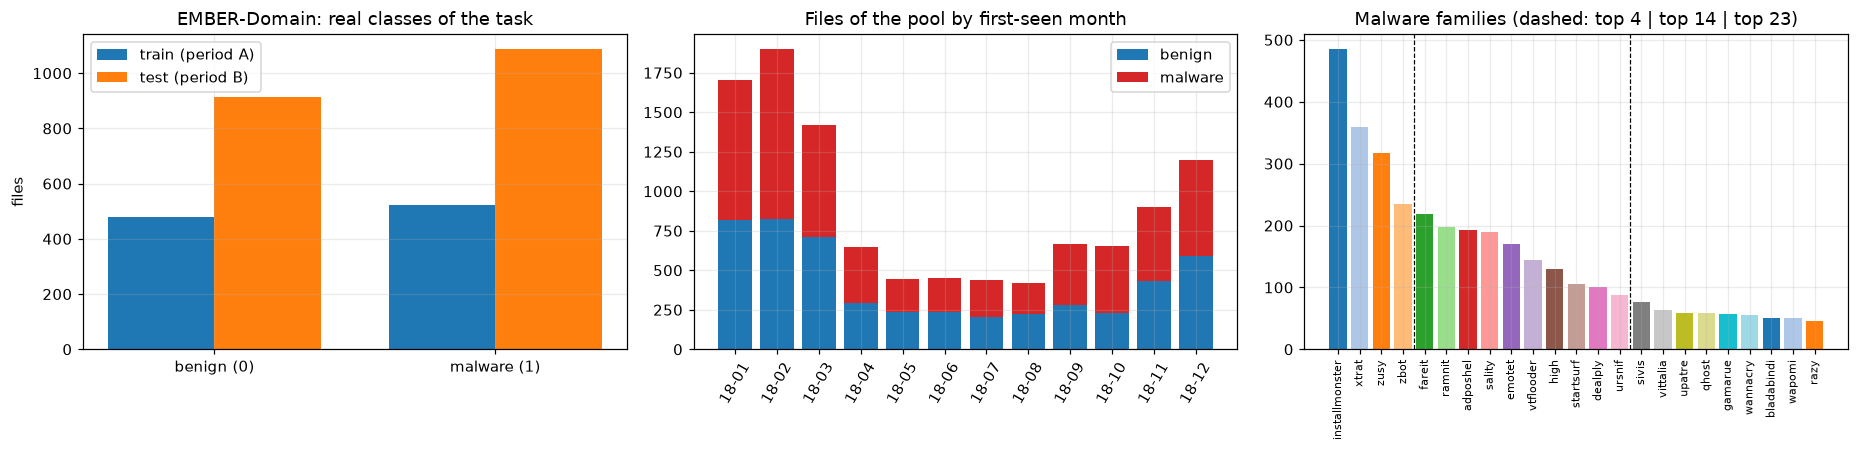

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
t = TASKS0["domain"]
w = 0.38
ax[0].bar(np.arange(2) - w/2, np.bincount(t["ytr"], minlength=2), w, label="train (period A)", color="tab:blue")
ax[0].bar(np.arange(2) + w/2, np.bincount(t["yte"], minlength=2), w, label="test (period B)", color="tab:orange")
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(["benign (0)", "malware (1)"]); ax[0].set_title("EMBER-Domain: real classes of the task"); ax[0].legend(); ax[0].set_ylabel("files")
months = sorted(set(monALL)); cnt = np.array([[((monALL == m) & (yALL == c)).sum() for m in months] for c in (0, 1)])
ax[1].bar(range(len(months)), cnt[0], color="tab:blue", label="benign"); ax[1].bar(range(len(months)), cnt[1], bottom=cnt[0], color="tab:red", label="malware")
ax[1].set_xticks(range(len(months))); ax[1].set_xticklabels([m[2:] for m in months], rotation=60); ax[1].set_title("Files of the pool by first-seen month"); ax[1].legend()
top = fam_counts.head(23)
ax[2].bar(range(len(top)), top.values, color=plt.cm.tab20(np.arange(len(top)) % 20))
ax[2].axvline(3.5, color="k", ls="--", lw=0.8); ax[2].axvline(13.5, color="k", ls="--", lw=0.8)
ax[2].set_xticks(range(len(top))); ax[2].set_xticklabels(top.index, rotation=90, fontsize=7)
ax[2].set_title("Malware families (dashed: top 4 | top 14 | top 23)")
plt.tight_layout(); plt.show()

### 2-D scatter of the real samples: EMBER-Domain (benign vs malware)

Left: the first two principal components of the *training* rows (period A, PCA fitted on them), the test rows (period B, newer files) drawn as crosses. Right: the same two coordinates scaled to [0, pi]
with the min-max scaler fitted on the training rows (test angles clipped), i.e. the first two qubit angles when angle scaling is used.

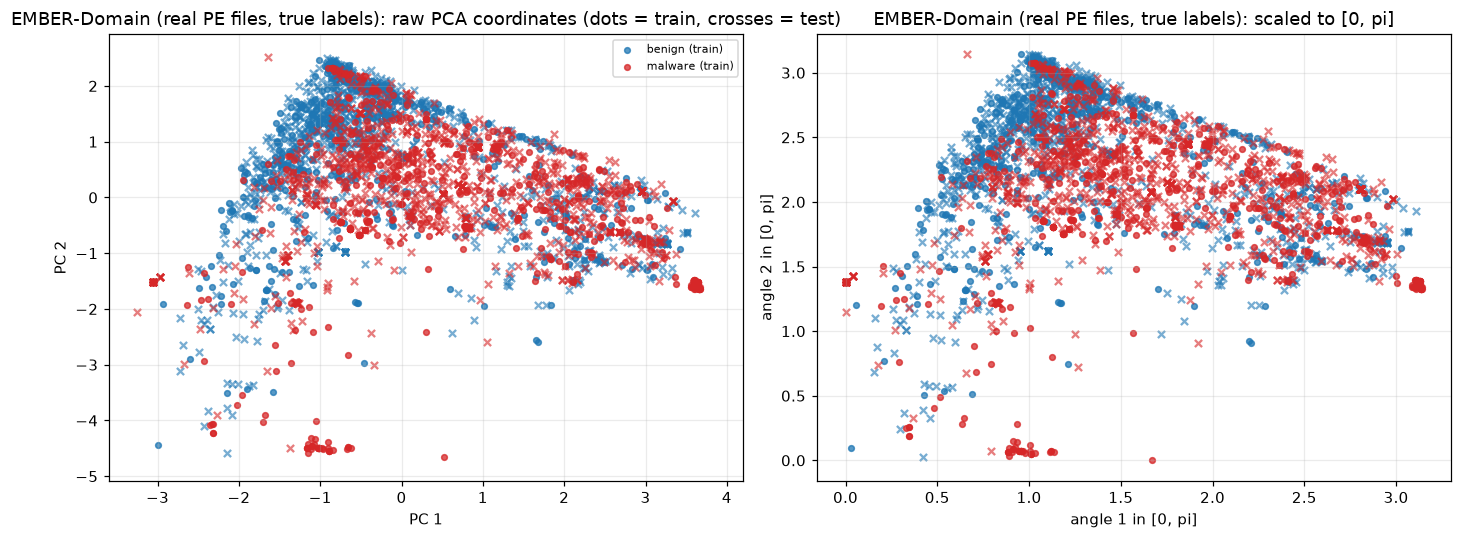

In [10]:
def scatter_task(t, title, max_labels=14):
    red = t["red"]; Ptr = red.pcs(XALL[t["tr"]]); Pte = red.pcs(XALL[t["te"]]); Atr = red.angles(XALL[t["tr"]]); Ate = red.angles(XALL[t["te"]])
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    K = t["K"]
    cmap = plt.cm.tab20 if K > 10 else plt.cm.tab10
    for k in range(K):
        col = ["tab:blue", "tab:red"][k] if K == 2 else cmap(k % 20)
        name = t["classes"][k]
        for a, (Z, Zt) in zip(ax, ((Ptr[:, :2], Pte[:, :2]), (Atr[:, :2], Ate[:, :2]))):
            m = t["ytr"] == k; a.scatter(Z[m, 0], Z[m, 1], s=14, color=col, alpha=0.75, label=f"{name} (train)" if k < max_labels else None)
            m = t["yte"] == k; a.scatter(Zt[m, 0], Zt[m, 1], s=22, marker="x", color=col, alpha=0.6)
    ax[0].set_xlabel("PC 1"); ax[0].set_ylabel("PC 2"); ax[0].set_title(title + ": raw PCA coordinates (dots = train, crosses = test)")
    ax[1].set_xlabel("angle 1 in [0, pi]"); ax[1].set_ylabel("angle 2 in [0, pi]"); ax[1].set_title(title + ": scaled to [0, pi]")
    ax[0].legend(fontsize=7, ncol=2 if K > 6 else 1, loc="best")
    lo, hi = np.percentile(Ptr[:, :2], 0.5, axis=0), np.percentile(Ptr[:, :2], 99.5, axis=0)       # zoom on the bulk; a few extreme real files are outside the frame
    pad = 0.08 * (hi - lo); ax[0].set_xlim(lo[0] - pad[0], hi[0] + pad[0]); ax[0].set_ylim(lo[1] - pad[1], hi[1] + pad[1])
    plt.tight_layout(); plt.show()

scatter_task(TASKS0["domain"], "EMBER-Domain (real PE files, true labels)")

### 2-D scatter of the real samples: EMBER-Class (coloured by malware family)

The multiclass tasks keep the family labels. The two panels are the same kind of plot as above for the top-4 and the top-14 families (PCA fitted on the training rows of each task).

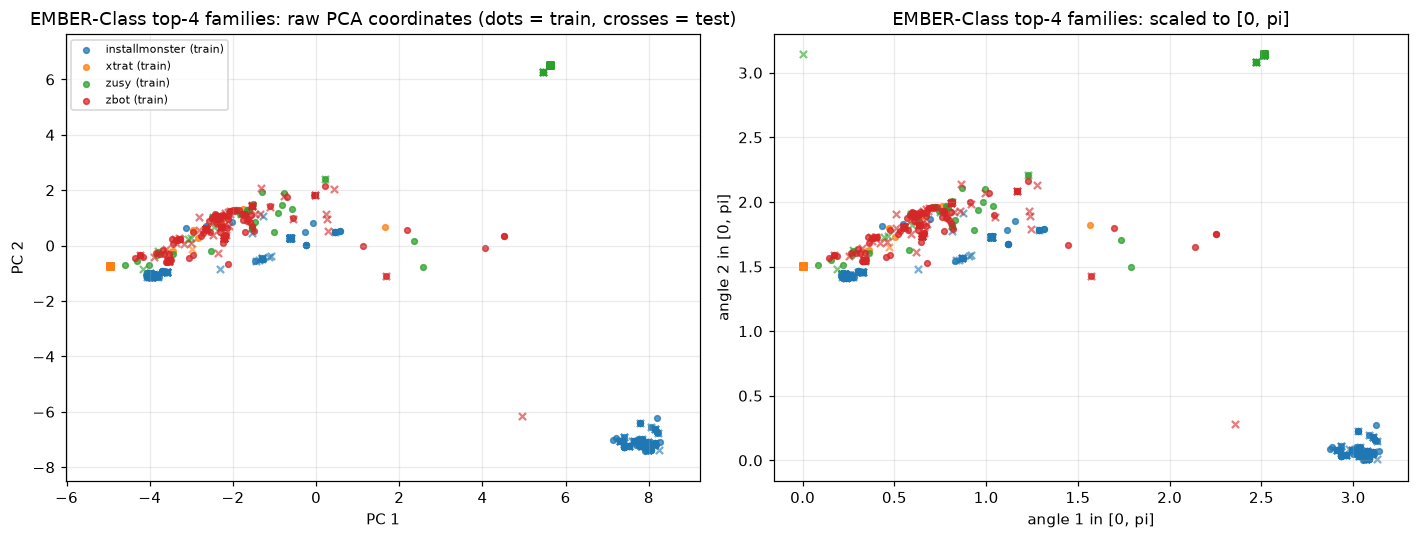

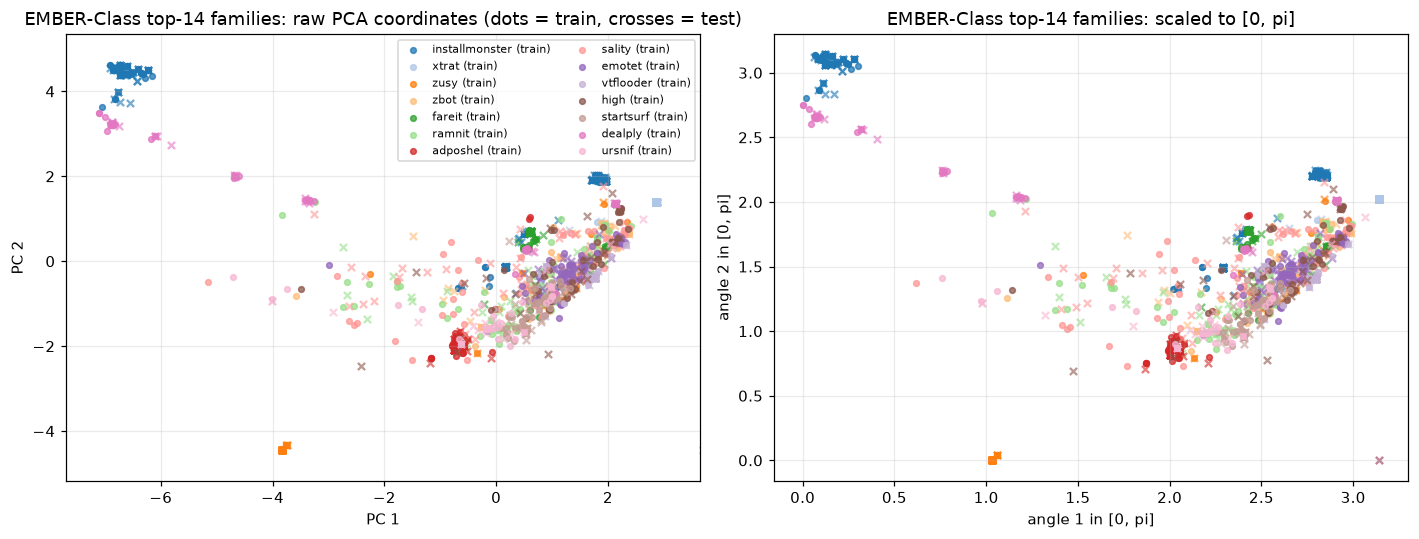

In [11]:
scatter_task(TASKS0["4"], "EMBER-Class top-4 families")
scatter_task(TASKS0["14"], "EMBER-Class top-14 families")

## Quantum Circuit Architecture

Both models are 16-qubit PennyLane circuits followed by a classical linear layer. This section (i) defines the two circuits exactly as the paper describes them, as real PennyLane QNodes on `default.qubit`,
(ii) draws them, (iii) prints qubits, depth and trainable parameters, and (iv) proves that the fast simulator used for training is **identical** to those QNodes (expectation values and gradients).

### Why a different simulator for training, and why it is exact

Simulating a 16-qubit state vector (65 536 amplitudes) for each sample and each gradient takes minutes per epoch on a CPU. These circuits, however, have a very special shape: product-state
encoding and `Rot` layers followed by **controlled gates on a ring**. We therefore store the state as a *matrix product state* (MPS, a chain of 16 small tensors) and apply every gate **exactly, without any truncation**:
a controlled-RX is written as `CRX = |0><0| (x) I + |1><1| (x) RX`, which applies a single-qubit operator on each of the two qubits and doubles the bond dimension between them. The bond dimension
stays at most 16, so one forward pass costs thousands of times fewer operations than the state vector, and PyTorch autograd gives exact gradients. Nothing is approximated: the cell further below checks the
expectation values and the gradients against PennyLane to about 1e-6.

### The exact tensor-network simulator (PyTorch)

In [12]:
NQ = 16
CT = torch.complex64
_I2 = torch.eye(2, dtype=CT)
_P = [torch.tensor([[1, 0], [0, 0]], dtype=CT), torch.tensor([[0, 0], [0, 1]], dtype=CT)]
_ZD = torch.tensor([1.0, -1.0], dtype=torch.float32)


def rx_m(a):
    a = torch.as_tensor(a, dtype=torch.float32); c, s = torch.cos(a / 2), torch.sin(a / 2); z = torch.zeros_like(c)
    return torch.stack([torch.complex(c, z), torch.complex(z, -s), torch.complex(z, -s), torch.complex(c, z)], -1).reshape(a.shape + (2, 2))

def ry_m(a):
    a = torch.as_tensor(a, dtype=torch.float32); c, s = torch.cos(a / 2), torch.sin(a / 2)
    return torch.complex(torch.stack([c, -s, s, c], -1).reshape(a.shape + (2, 2)), torch.zeros(a.shape + (2, 2)))

def rz_m(a):
    a = torch.as_tensor(a, dtype=torch.float32); z = torch.zeros_like(a)
    e, e2 = torch.polar(torch.ones_like(a), -a / 2), torch.polar(torch.ones_like(a), a / 2)
    zc = torch.complex(z, z)
    return torch.stack([e, zc, zc, e2], -1).reshape(a.shape + (2, 2))

def rot_m(phi, theta, omega):                  # PennyLane Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi)
    return rz_m(omega) @ ry_m(theta) @ rz_m(phi)


def _gate1(T, M):                              # single-qubit gate on one site: T (B,l,2,r), M (2,2) or (B,2,2)
    return torch.einsum("st,bltr->blsr", M, T) if M.dim() == 2 else torch.einsum("bst,bltr->blsr", M, T)

def _two_site(T, c, t, M):
    """Exact controlled gate (control c, target t, M on the target): operator-Schmidt decomposition
    sum_a P_a(control) (x) B_a(target); intermediate sites carry the index a through an identity."""
    i, j = min(c, t), max(c, t)
    ops_c = [_P[0], _P[1]]; ops_t = [_I2, M.to(CT)]
    op_i = ops_c if i == c else ops_t
    op_j = ops_c if j == c else ops_t
    Ti = torch.stack([torch.einsum("st,bltr->blsr", op_i[a], T[i]) for a in (0, 1)], dim=-1)          # (B,l,2,r,a)
    T[i] = Ti.reshape(Ti.shape[0], Ti.shape[1], 2, Ti.shape[3] * 2)                                    # right bond = (r, a)
    for k in range(i + 1, j):
        X = T[k][:, :, None, :, :, None] * _I2.real.to(CT)[None, None, :, None, None, :]            # (B,l,a,s,r,a')
        T[k] = X.reshape(X.shape[0], X.shape[1] * 2, 2, X.shape[4] * 2)
    Tj = torch.stack([torch.einsum("st,bltr->blsr", op_j[a], T[j]) for a in (0, 1)], dim=2)          # (B,l,a,s,r)
    T[j] = Tj.reshape(Tj.shape[0], Tj.shape[1] * 2, 2, Tj.shape[4])                                    # left bond = (l, a)


def expectation_z(T, qubits):
    """<Z_q> for q in qubits of the MPS T (assumed normalised) via left/right environments."""
    B = T[0].shape[0]
    L = [torch.ones(B, 1, 1, dtype=CT)]
    for k in range(NQ - 1):
        L.append(torch.einsum("bpsx,bpq,bqsy->bxy", T[k].conj(), L[-1], T[k]))
    R = [None] * (NQ + 1); R[NQ] = torch.ones(B, 1, 1, dtype=CT)
    for k in range(NQ - 1, 0, -1):
        R[k] = torch.einsum("bpsx,bxy,bqsy->bpq", T[k].conj(), R[k + 1], T[k])
    out = []
    for q in qubits:
        out.append(torch.einsum("bpsx,s,bpq,bqsy,bxy->b", T[q].conj(), _ZD.to(CT), L[q], T[q], R[q + 1]).real)
    norm = torch.einsum("bpsx,bpq,bqsy,bxy->b", T[NQ - 1].conj(), L[NQ - 1], T[NQ - 1], R[NQ]).real
    return torch.stack(out, dim=1), norm


def _enc(x, kind):
    out = []
    for q in range(NQ):
        a = x[:, q]
        out.append(rx_m(a) if kind == "X" else rz_m(a) @ ry_m(a) @ rx_m(a))     # "XYZ": RX, then RY, then RZ, same angle
    return out


def run_circuit(program, measured, enc_kind, x, w_rot, w_crx):
    B = x.shape[0]
    T = []
    for q in range(NQ):
        t = torch.zeros(B, 1, 2, 1, dtype=CT); t[:, 0, 0, 0] = 1.0; T.append(t)
    E = _enc(x, enc_kind) if enc_kind else None
    for op in program:
        if op[0] == "ROT":
            _, q, enc, i = op
            M = rot_m(w_rot[i, 0], w_rot[i, 1], w_rot[i, 2])
            if enc: M = M[None] @ E[q]
            T[q] = _gate1(T[q], M)
        else:
            _, c, t, i = op
            _two_site(T, c, t, rx_m(w_crx[i]))
    ez, norm = expectation_z(T, measured)
    return ez, norm, max(int(t.shape[1]) for t in T)


# ---------------------------------------------------------------- the two architectures of the paper (gate lists)
def qmlp_program():
    prog = []
    for l in range(2):
        for q in range(NQ): prog.append(("ROT", q, "X", l * NQ + q))               # RX(x_q) encoding, then Rot
        for q in range(NQ): prog.append(("CRX", q, (q + 1) % NQ, l * NQ + q))      # ring of CRX
    return prog                                                                     # n_rot = 32, n_crx = 32, all 16 qubits measured
QMLP_MEASURED = list(range(NQ))

def qcnn_program():
    prog = []
    for q in range(NQ): prog.append(("ROT", q, "XYZ", q))                           # RX,RY,RZ encoding + convolution Rot
    for q in range(NQ): prog.append(("CRX", q, (q + 1) % NQ, q))                    # convolution entanglement (ring)
    keep1 = list(range(0, NQ, 2))                                                   # pooling 1: keep qubits 0,2,...,14
    for j, q in enumerate(keep1): prog.append(("ROT", q, None, NQ + j))
    for j, q in enumerate(keep1): prog.append(("CRX", q, keep1[(j + 1) % 8], NQ + j))
    return prog                                                                     # n_rot = 24, n_crx = 24; pooling 2 keeps 0,4,8,12
QCNN_MEASURED = [0, 4, 8, 12]


class QModel(torch.nn.Module):
    """quantum layer (16 qubits) -> Linear -> LogSoftmax, as in the paper (PennyLane TorchLayer-style hybrid model)."""
    def __init__(self, kind, n_classes, seed):
        super().__init__()
        g = torch.Generator().manual_seed(seed)
        if kind == "QMLP":
            self.program, self.measured, self.enc, n_rot, n_crx = qmlp_program(), QMLP_MEASURED, "X", 32, 32
        else:
            self.program, self.measured, self.enc, n_rot, n_crx = qcnn_program(), QCNN_MEASURED, "XYZ", 24, 24
        # PennyLane TorchLayer default initialisation: uniform on [0, 2*pi)
        self.w_rot = torch.nn.Parameter(torch.rand(n_rot, 3, generator=g) * 2 * np.pi)
        self.w_crx = torch.nn.Parameter(torch.rand(n_crx, generator=g) * 2 * np.pi)
        torch.manual_seed(seed)
        self.fc = torch.nn.Linear(len(self.measured), n_classes)
        self.lsm = torch.nn.LogSoftmax(dim=1)

    def features(self, x):
        return run_circuit(self.program, self.measured, self.enc, x, self.w_rot, self.w_crx)[0]

    def forward(self, x):
        return self.lsm(self.fc(self.features(x)))

### The two circuits as real PennyLane QNodes

* **QMLP** (paper Figure 1a): `AngleEmbedding(RX)` of the 16 PCA values, trainable `Rot` on all 16 qubits, trainable `CRX` on the ring `q -> q+1 (mod 16)`; this block is **repeated once** with new parameters
  (data re-uploading); Pauli-Z expectation values of all 16 qubits.
* **QCNN** (paper Figure 1b): angle embedding with `RX`, then `RY`, then `RZ`; convolution = trainable `Rot` on all qubits + ring of trainable `CRX`; pooling keeps the even qubits 0, 2, ..., 14;
  trainable `Rot` on the 8 survivors + ring of `CRX` among them (`# CHOICE:` 0->2->4->...->14->0); pooling keeps qubits 0, 4, 8, 12; Pauli-Z expectation values of these 4 qubits.
  Pooled-away qubits are simply no longer touched or measured (they are traced out).

In [13]:
import pennylane as qml
print("pennylane", qml.__version__)
dev16 = qml.device("default.qubit", wires=N_QUBITS)

@qml.qnode(dev16, interface="torch", diff_method="backprop")
def qmlp_qnode(x, w_rot, w_crx):
    for layer in range(2):                                                  # block repeated twice (data re-uploading)
        qml.AngleEmbedding(x, wires=range(N_QUBITS), rotation="X")          # RX(x_q) on every qubit
        for q in range(N_QUBITS):
            qml.Rot(w_rot[layer * N_QUBITS + q, 0], w_rot[layer * N_QUBITS + q, 1], w_rot[layer * N_QUBITS + q, 2], wires=q)
        for q in range(N_QUBITS):
            qml.CRX(w_crx[layer * N_QUBITS + q], wires=[q, (q + 1) % N_QUBITS])   # CHOICE: ring q -> q+1 (mod 16)
    return [qml.expval(qml.PauliZ(q)) for q in range(N_QUBITS)]

@qml.qnode(dev16, interface="torch", diff_method="backprop")
def qcnn_qnode(x, w_rot, w_crx):
    for rot in ("X", "Y", "Z"):                                             # RX, RY, RZ angle embedding
        qml.AngleEmbedding(x, wires=range(N_QUBITS), rotation=rot)
    for q in range(N_QUBITS):                                               # convolution layer
        qml.Rot(w_rot[q, 0], w_rot[q, 1], w_rot[q, 2], wires=q)
    for q in range(N_QUBITS):
        qml.CRX(w_crx[q], wires=[q, (q + 1) % N_QUBITS])
    keep = list(range(0, N_QUBITS, 2))                                      # pooling 1: keep qubits 0, 2, ..., 14
    for j, q in enumerate(keep):
        qml.Rot(w_rot[N_QUBITS + j, 0], w_rot[N_QUBITS + j, 1], w_rot[N_QUBITS + j, 2], wires=q)
    for j, q in enumerate(keep):
        qml.CRX(w_crx[N_QUBITS + j], wires=[q, keep[(j + 1) % len(keep)]])  # CHOICE: ring among the 8 survivors
    return [qml.expval(qml.PauliZ(q)) for q in [0, 4, 8, 12]]               # pooling 2: keep qubits 0, 4, 8, 12

CIRCUITS = {"QMLP": qmlp_qnode, "QCNN": qcnn_qnode}
_demo = {k: QModel(k, 2, 0) for k in CIRCUITS}
x_demo = torch.tensor(np.random.default_rng(0).uniform(0, np.pi, N_QUBITS), dtype=torch.float32)
for kind, qn in CIRCUITS.items():
    m = _demo[kind]
    sp = qml.specs(qn, level="device")(x_demo, m.w_rot.detach(), m.w_crx.detach())
    res = sp["resources"]
    n_params = m.w_rot.numel() + m.w_crx.numel()
    print(f"{kind}: qubits = {N_QUBITS} | measured qubits = {len(m.measured)} | circuit depth = {res.depth} | gates = {res.num_gates} | "
          f"trainable quantum parameters = {n_params} ({m.w_rot.numel()} Rot angles + {m.w_crx.numel()} CRX angles)")
    print(f"      + classical Linear({len(m.measured)} -> n_classes): {len(m.measured)} x n_classes weights + n_classes biases")

pennylane 0.45.1
QMLP: qubits = 16 | measured qubits = 16 | circuit depth = 36 | gates = 96 | trainable quantum parameters = 128 (96 Rot angles + 32 CRX angles)
      + classical Linear(16 -> n_classes): 16 x n_classes weights + n_classes biases
QCNN: qubits = 16 | measured qubits = 4 | circuit depth = 29 | gates = 96 | trainable quantum parameters = 96 (72 Rot angles + 24 CRX angles)
      + classical Linear(4 -> n_classes): 4 x n_classes weights + n_classes biases


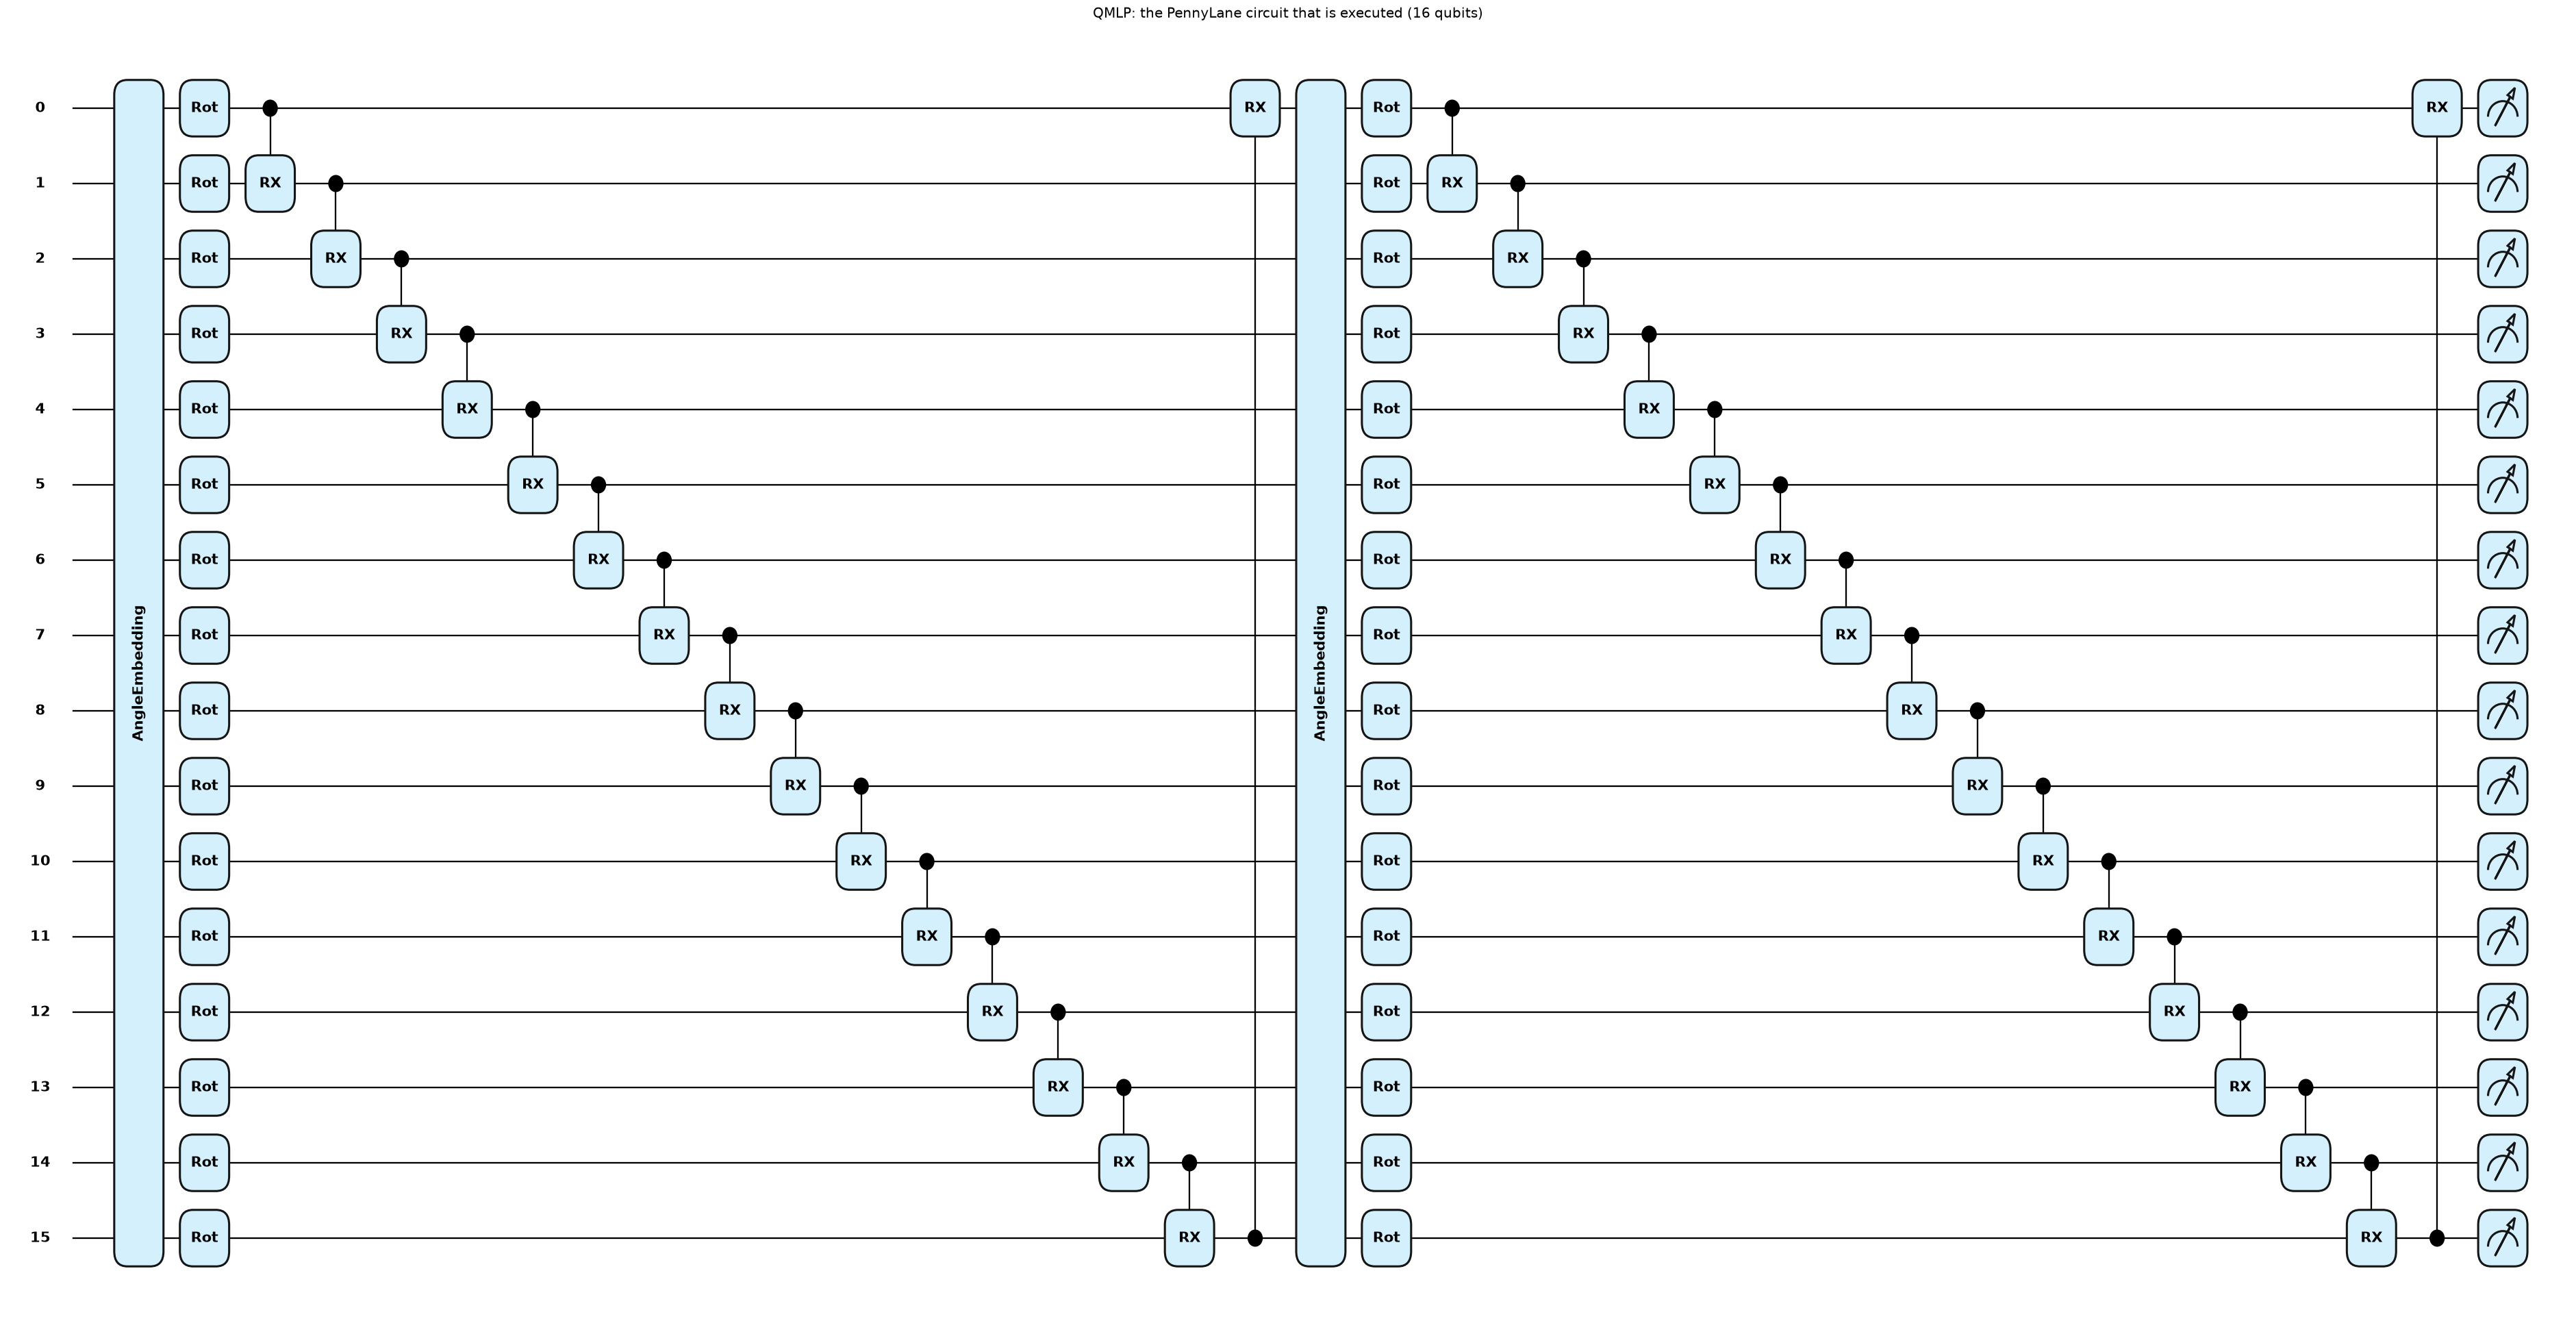

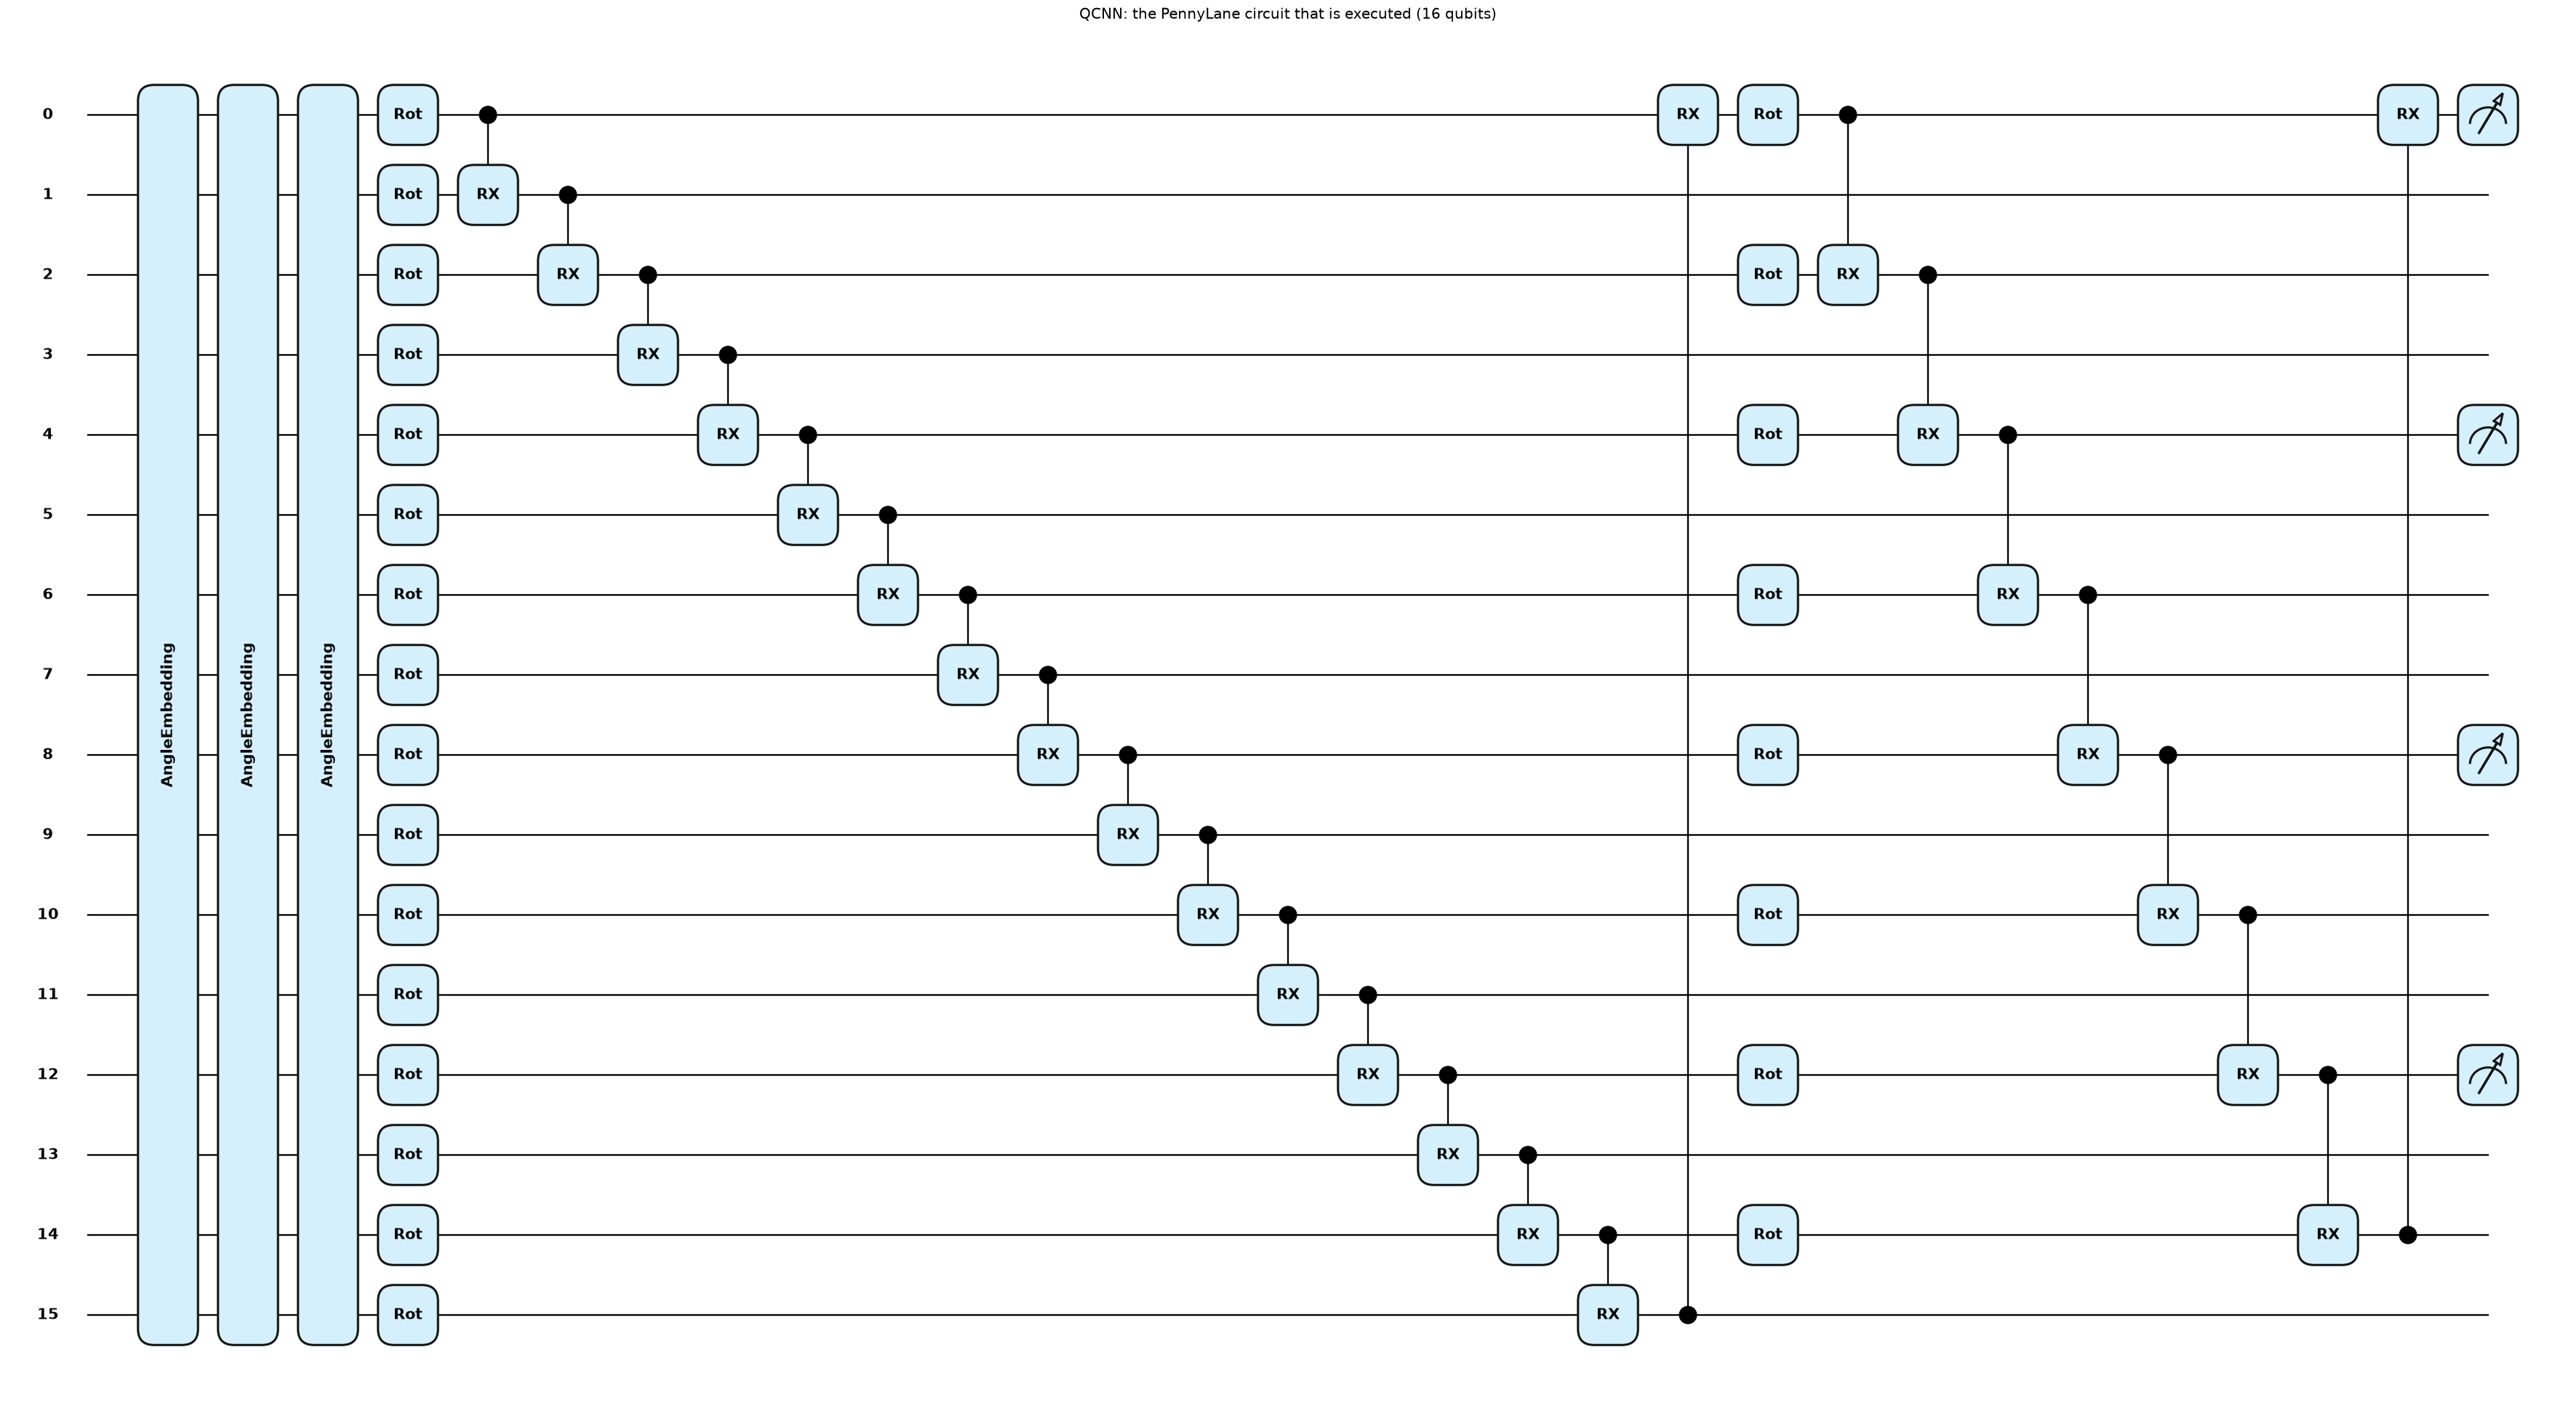

In [14]:
for kind, qn in CIRCUITS.items():
    m = _demo[kind]
    fig, ax = qml.draw_mpl(qn, decimals=None, style="pennylane")(x_demo, m.w_rot.detach(), m.w_crx.detach())
    fig.set_size_inches(min(34, fig.get_size_inches()[0]), fig.get_size_inches()[1])
    fig.suptitle(f"{kind}: the PennyLane circuit that is executed (16 qubits)", y=1.02, fontsize=13)
    plt.show()

### Exactness check: tensor-network simulator vs the real PennyLane QNodes

For random inputs and random weights we compare (a) the Pauli-Z expectation values and (b) the gradient of an arbitrary weighted sum of them with respect to every trainable angle, computed by
PennyLane (`default.qubit`, full state vector, back-propagation) and by the simulator used for training. The assertion fails the whole notebook if they disagree.

In [15]:
def check_equivalence(kind, n_samples=3, seed=0):
    r = np.random.default_rng(seed)
    m = QModel(kind, 2, seed); qn = CIRCUITS[kind]
    x = r.uniform(0, np.pi, (n_samples, N_QUBITS)); g = r.normal(size=(n_samples, len(m.measured)))
    wr = r.uniform(0, 2 * np.pi, tuple(m.w_rot.shape)); wc = r.uniform(0, 2 * np.pi, m.w_crx.shape[0])
    # (1) exact tensor-network simulator (float32)
    wr_a = torch.tensor(wr, dtype=torch.float32, requires_grad=True); wc_a = torch.tensor(wc, dtype=torch.float32, requires_grad=True)
    ez, norm, chi = run_circuit(m.program, m.measured, m.enc, torch.tensor(x, dtype=torch.float32), wr_a, wc_a)
    (ez * torch.tensor(g, dtype=torch.float32)).sum().backward()
    # (2) PennyLane default.qubit (float64 state vector), one QNode call per sample
    wr_t = torch.tensor(wr, requires_grad=True); wc_t = torch.tensor(wc, requires_grad=True)
    ref, tot = [], 0
    for b in range(n_samples):
        o = torch.stack(qn(torch.tensor(x[b]), wr_t, wc_t)); ref.append(o.detach().numpy())
        tot = tot + (o * torch.tensor(g[b])).sum()
    tot.backward()
    d_exp = float(np.abs(np.array(ref) - ez.detach().numpy()).max())
    d_gr = float(max(np.abs(wr_t.grad.numpy() - wr_a.grad.numpy()).max(), np.abs(wc_t.grad.numpy() - wc_a.grad.numpy()).max()))
    return d_exp, d_gr, float((norm - 1).abs().max()), chi

for kind in CIRCUITS:
    d_exp, d_gr, d_norm, chi = check_equivalence(kind)
    print(f"{kind}: max |<Z> difference| = {d_exp:.2e} | max |gradient difference| = {d_gr:.2e} | norm error = {d_norm:.1e} | largest MPS bond dimension = {chi}")
    assert d_exp < 1e-4 and d_gr < 1e-3, f"{kind}: tensor-network simulator disagrees with PennyLane"
print("The training simulator reproduces the PennyLane QNodes (expectation values and gradients).")

QMLP: max |<Z> difference| = 4.02e-07 | max |gradient difference| = 8.10e-07 | norm error = 2.4e-07 | largest MPS bond dimension = 16


QCNN: max |<Z> difference| = 4.66e-07 | max |gradient difference| = 5.07e-07 | norm error = 8.3e-07 | largest MPS bond dimension = 16
The training simulator reproduces the PennyLane QNodes (expectation values and gradients).


## 3. Training code, metrics and classical baselines

The hybrid model is `quantum circuit (16 qubits) -> Linear -> LogSoftmax`, trained end-to-end with Adam on the negative log-likelihood, as in the paper. The metrics are the paper's: accuracy,
**macro-averaged** precision, recall and F1, macro false-positive and false-negative rates (in the binary case they coincide up to rounding, as in the paper's Table II) and ROC-AUC
(one-vs-rest, macro, for the multiclass tasks). The classical baselines see **exactly the same 16 inputs** as the quantum models; a random forest on all 2 381 raw features is added as a reference.

In [16]:
def fit_quantum(kind, Xtr, ytr, K, seed, epochs, bs, lr):
    torch.manual_seed(seed)
    model = QModel(kind, K, seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lossf = torch.nn.NLLLoss()
    Xt, yt = torch.tensor(Xtr), torch.tensor(ytr, dtype=torch.long)
    g = torch.Generator().manual_seed(seed)
    losses, epoch_loss, t0 = [], [], time.time()
    for ep in range(epochs):
        perm = torch.randperm(len(Xt), generator=g); tot = 0.0
        for a in range(0, len(Xt), bs):
            idx = perm[a:a + bs]
            opt.zero_grad(); loss = lossf(model(Xt[idx]), yt[idx]); loss.backward(); opt.step()
            losses.append(loss.item()); tot += loss.item() * len(idx)
        epoch_loss.append(tot / len(Xt))
    return model, dict(losses=losses, epoch_loss=epoch_loss, train_time=time.time() - t0)

@torch.no_grad()
def predict_proba_q(model, X, bs=256):
    out = [model(torch.tensor(X[a:a + bs])) for a in range(0, len(X), bs)]
    return torch.cat(out).exp().numpy()

def metrics_from(y, proba, K):
    pred = proba.argmax(1)
    cm = confusion_matrix(y, pred, labels=list(range(K)))
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=list(range(K)), average="macro", zero_division=0)
    fpr, fnr = [], []
    for c in range(K):
        tp = cm[c, c]; fn = cm[c].sum() - tp; fp = cm[:, c].sum() - tp; tn = cm.sum() - tp - fn - fp
        fpr.append(fp / (fp + tn) if fp + tn else 0.0); fnr.append(fn / (fn + tp) if fn + tp else 0.0)
    try:
        auc = roc_auc_score(y, proba[:, 1]) if K == 2 else roc_auc_score(y, proba / proba.sum(1, keepdims=True), multi_class="ovr", average="macro", labels=list(range(K)))
    except ValueError:
        auc = float("nan")
    m = dict(acc=100 * accuracy_score(y, pred), prec=100 * p, rec=100 * r, f1=100 * f, fpr=100 * np.mean(fpr), fnr=100 * np.mean(fnr), auc=100 * auc)
    return m, cm

def baselines(Ftr, ytr, Fte, K, Rtr, Rte, seed):
    # classical models on the SAME 16 inputs (Ftr/Fte) and a random forest on all 2381 raw features (Rtr/Rte)
    out = {}
    t0 = time.time(); m = RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=1).fit(Ftr, ytr)
    out["RF (16 inputs)"] = (m.predict_proba(Fte), time.time() - t0)
    t0 = time.time(); m = SVC(kernel="rbf", C=1.0, probability=True, random_state=seed).fit(Ftr, ytr)
    out["SVC rbf (16 inputs)"] = (m.predict_proba(Fte), time.time() - t0)
    t0 = time.time(); m = LogisticRegression(max_iter=2000).fit(Ftr, ytr)
    out["LogReg (16 inputs)"] = (m.predict_proba(Fte), time.time() - t0)
    t0 = time.time(); m = RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=1).fit(Rtr, ytr)
    out["RF (all 2381 features)"] = (m.predict_proba(Rte), time.time() - t0)
    return out
print("training / metric / baseline functions defined")

training / metric / baseline functions defined


## 4. Choosing the learning rate and the angle scaling on a validation split

The paper does not state the learning rate, and it is ambiguous whether the PCA outputs are fed to the rotation gates directly or rescaled. Both are tuned **on validation rows that are neither training nor test rows**
(the evaluation period B is never touched): each model is trained briefly on the task's training rows with each setting and scored on 600 validation rows. The angle mode with the best average validation accuracy is used everywhere; learning rates are chosen per model (binary task on EMBER-Domain validation rows from period A that are not training rows; multiclass tasks on rows of the 14-family pool that are neither training nor test rows).

In [17]:
tune_rows, t0 = [], time.time()

def tune_task(task, val_idx, yval, modes, tag):
    # train briefly on the task's training rows, score on validation rows that are neither training nor test rows
    red = task["red"]; Rtr, Rva = XALL[task["tr"][:N_TUNE_TRAIN]], XALL[val_idx]; ytr = task["ytr"][:N_TUNE_TRAIN]
    for kind in ("QMLP", "QCNN"):
        for mode in modes:
            Ftr, Fva = red.encode(Rtr, mode), red.encode(Rva, mode)
            for lr in TUNE_LR_GRID:
                model, info = fit_quantum(kind, Ftr, ytr, task["K"], SEED, TUNE_EPOCHS, BATCH, lr)
                acc = 100 * (predict_proba_q(model, Fva).argmax(1) == yval).mean()
                tune_rows.append(dict(task=tag, model=kind, angle_mode=mode, lr=lr, val_acc=acc, final_train_loss=info["epoch_loss"][-1]))
                print(f"  [{tag}] {kind} angles={mode:5s} lr={lr:<5} -> validation accuracy {acc:.1f} % (train loss {info['epoch_loss'][-1]:.3f}, {time.time()-t0:.0f} s)", flush=True)

# (a) EMBER-Domain: validation rows from period A that are not training rows (period B is never touched)
t_dom = TASKS0["domain"]
rA = np.random.default_rng(SEED).permutation(np.setdiff1d(iA, t_dom["tr"]))[:N_VAL]
tune_task(t_dom, rA, yALL[rA], TUNE_ANGLE_GRID, "domain")
tdf = pd.DataFrame(tune_rows)
ANGLE_MODE = tdf.groupby(["angle_mode", "model"]).val_acc.max().groupby("angle_mode").mean().idxmax()
LR_DOMAIN = {k: float(tdf[(tdf.model == k) & (tdf.angle_mode == ANGLE_MODE)].sort_values("val_acc").iloc[-1].lr) for k in ("QMLP", "QCNN")}
# (b) multiclass: learning rate only (angle mode fixed), on the 14-family task with its own validation rows
t14 = TASKS0["14"]; top14 = list(t14["classes"])
rest = np.setdiff1d(pool_idx[np.isin(famALL[pool_idx], top14)], np.concatenate([t14["tr"], t14["te"]]))
rest = np.random.default_rng(SEED).permutation(rest)[:N_VAL]
yrest = np.array([top14.index(f) for f in famALL[rest]])
tune_task(t14, rest, yrest, [ANGLE_MODE], "class14")
tdf = pd.DataFrame(tune_rows)
LR_CLASS = {k: float(tdf[(tdf.model == k) & (tdf.task == "class14")].sort_values("val_acc").iloc[-1].lr) for k in ("QMLP", "QCNN")}
LR_BY_TASK = {"EMBER-Domain": LR_DOMAIN, "EMBER-Class4": LR_CLASS, "EMBER-Class14": LR_CLASS, "EMBER-Class23": LR_CLASS}
print("\nchosen on validation rows -> angle mode:", ANGLE_MODE, "| learning rates, binary:", LR_DOMAIN, "| multiclass:", LR_CLASS)
print(f"validation rows: domain {len(rA)}, class14 {len(rest)}")
display(tdf.round(3))

  [domain] QMLP angles=paper lr=0.01  -> validation accuracy 75.8 % (train loss 0.554, 23 s)


  [domain] QMLP angles=paper lr=0.05  -> validation accuracy 73.7 % (train loss 0.456, 40 s)


  [domain] QMLP angles=paper lr=0.1   -> validation accuracy 73.0 % (train loss 0.473, 58 s)


  [domain] QMLP angles=pi    lr=0.01  -> validation accuracy 73.8 % (train loss 0.606, 74 s)


  [domain] QMLP angles=pi    lr=0.05  -> validation accuracy 67.5 % (train loss 0.469, 91 s)


...

  [class14] QCNN angles=paper lr=0.01  -> validation accuracy 30.5 % (train loss 2.328, 259 s)


  [class14] QCNN angles=paper lr=0.05  -> validation accuracy 36.8 % (train loss 1.728, 273 s)


  [class14] QCNN angles=paper lr=0.1   -> validation accuracy 50.3 % (train loss 1.523, 287 s)



chosen on validation rows -> angle mode: paper | learning rates, binary: {'QMLP': 0.01, 'QCNN': 0.1} | multiclass: {'QMLP': 0.1, 'QCNN': 0.1}
validation rows: domain 600, class14 600


,task,model,angle_mode,lr,val_acc,final_train_loss
0,domain,QMLP,paper,0.01,75.833,0.554
1,domain,QMLP,paper,0.05,73.667,0.456
2,domain,QMLP,paper,0.10,73.000,0.473
3,domain,QMLP,pi,0.01,73.833,0.606
4,domain,QMLP,pi,0.05,67.500,0.469
5,domain,QMLP,pi,0.10,73.000,0.490
6,domain,QCNN,paper,0.01,56.000,0.683
7,domain,QCNN,paper,0.05,60.167,0.586
8,domain,QCNN,paper,0.10,73.833,0.509
9,domain,QCNN,pi,0.01,52.500,0.694


## 5. Running the experiments

For every seed and every task (EMBER-Domain, EMBER-Class with 4, 14 and 23 families) the notebook trains QMLP and QCNN and the classical baselines, and scores them on the held-out evaluation rows.
Wall-clock training times are recorded (QCNN is expected to be cheaper because it has fewer gates and measures only four qubits).

In [18]:
RESULTS, CMS, LOSSES, MODELS = [], {}, {}, {}
t_run = time.time()
for seed in SEEDS:
    for spec in TASK_SPECS:
        task = TASKS0[spec] if seed == SEEDS[0] else build_task(spec, seed)
        K, red = task["K"], task["red"]
        Rtr, Rte = XALL[task["tr"]], XALL[task["te"]]
        Ftr, Fte = red.encode(Rtr, ANGLE_MODE), red.encode(Rte, ANGLE_MODE)
        for name, (proba, secs) in baselines(Ftr, task["ytr"], Fte, K, Rtr, Rte, seed).items():
            m, cm = metrics_from(task["yte"], proba, K)
            RESULTS.append(dict(task=task["name"], K=K, model=name, seed=seed, train_s=secs, **m))
            if seed == SEEDS[0]: CMS[(task["name"], name)] = cm
        for kind in ("QMLP", "QCNN"):
            model, info = fit_quantum(kind, Ftr, task["ytr"], K, seed, EPOCHS, BATCH, LR_BY_TASK[task["name"]][kind])
            t1 = time.time(); proba = predict_proba_q(model, Fte); t_pred = time.time() - t1
            m, cm = metrics_from(task["yte"], proba, K)
            RESULTS.append(dict(task=task["name"], K=K, model=kind, seed=seed, train_s=info["train_time"], pred_s=t_pred, **m))
            if seed == SEEDS[0]: CMS[(task["name"], kind)] = cm; LOSSES[(task["name"], kind)] = info["losses"]
            print(f"seed {seed} | {task['name']:15s} | {kind}: acc {m['acc']:5.1f} | F1 {m['f1']:5.1f} | AUC {m['auc']:5.1f} | train {info['train_time']:6.1f} s "
                  f"({info['train_time']/EPOCHS:.1f} s/epoch) | elapsed {(time.time()-t_run)/60:.1f} min", flush=True)
RES = pd.DataFrame(RESULTS)
print(f"\nall experiments finished in {(time.time()-t_run)/60:.1f} min")

seed 0 | EMBER-Domain    | QMLP: acc  71.1 | F1  70.9 | AUC  82.8 | train  177.3 s (14.8 s/epoch) | elapsed 3.1 min


seed 0 | EMBER-Domain    | QCNN: acc  70.7 | F1  70.3 | AUC  79.3 | train  129.8 s (10.8 s/epoch) | elapsed 5.3 min


seed 0 | EMBER-Class4    | QMLP: acc  95.9 | F1  95.3 | AUC  99.2 | train  176.9 s (14.7 s/epoch) | elapsed 8.4 min


seed 0 | EMBER-Class4    | QCNN: acc  94.5 | F1  93.6 | AUC  99.3 | train  128.4 s (10.7 s/epoch) | elapsed 10.5 min


seed 0 | EMBER-Class14   | QMLP: acc  76.6 | F1  69.8 | AUC  95.9 | train  174.8 s (14.6 s/epoch) | elapsed 13.6 min


...

seed 1 | EMBER-Class14   | QMLP: acc  76.2 | F1  70.5 | AUC  95.8 | train  199.9 s (16.7 s/epoch) | elapsed 35.8 min


seed 1 | EMBER-Class14   | QCNN: acc  66.6 | F1  57.2 | AUC  91.0 | train  157.6 s (13.1 s/epoch) | elapsed 38.4 min


seed 1 | EMBER-Class23   | QMLP: acc  69.4 | F1  57.3 | AUC  94.3 | train  203.8 s (17.0 s/epoch) | elapsed 42.1 min


seed 1 | EMBER-Class23   | QCNN: acc  58.0 | F1  36.0 | AUC  89.5 | train  127.5 s (10.6 s/epoch) | elapsed 44.2 min



all experiments finished in 44.2 min


## 6. Results

### Training curves (first seed)

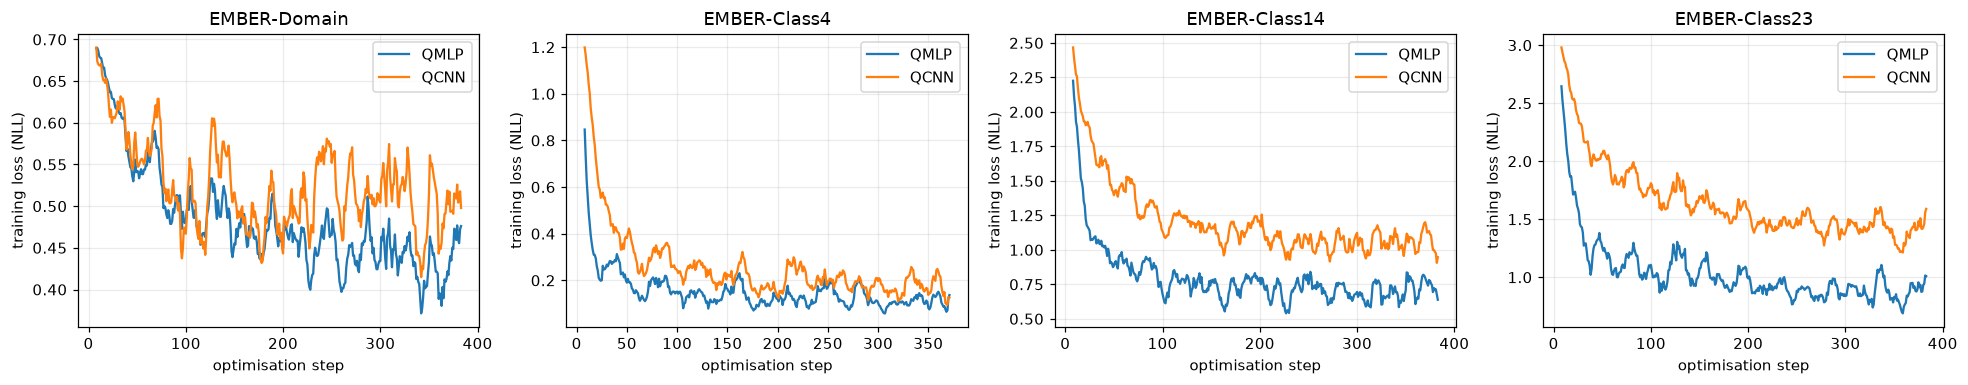

In [19]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
for a, spec in zip(ax, TASK_SPECS):
    nm = TASKS0[spec]["name"]
    for kind, col in (("QMLP", "tab:blue"), ("QCNN", "tab:orange")):
        l = np.array(LOSSES[(nm, kind)]); k = max(1, len(l) // 40)
        sm = np.convolve(l, np.ones(k) / k, mode="valid")
        a.plot(np.arange(len(sm)) + k - 1, sm, color=col, label=kind)
    a.set_title(nm); a.set_xlabel("optimisation step"); a.set_ylabel("training loss (NLL)"); a.legend()
plt.tight_layout(); plt.show()

### Metrics (mean +- std over seeds), the analogue of the paper's Tables I and II

In [20]:
def fmt(g, col):
    mu, sd = g[col].mean(), g[col].std(ddof=0)
    return f"{mu:.1f} +- {sd:.1f}" if len(g) > 1 else f"{mu:.1f}"
cols = ["acc", "prec", "rec", "f1", "fpr", "fnr", "auc"]
for spec in TASK_SPECS:
    tname = TASKS0[spec]["name"]
    sub = RES[RES.task == tname]
    rows = {m: {c: fmt(g, c) for c in cols} | {"train s": f"{g.train_s.mean():.1f}"} for m, g in sub.groupby("model", sort=False)}
    print(f"\n{tname}  (train {len(TASKS0[spec]['tr'])} rows, test {len(TASKS0[spec]['te'])} rows, {len(SEEDS)} seed(s))")
    display(pd.DataFrame(rows).T.rename(columns={"acc": "accuracy", "prec": "precision", "rec": "recall", "f1": "F1", "fpr": "FPR", "fnr": "FNR", "auc": "ROC-AUC"}))


EMBER-Domain  (train 1000 rows, test 2000 rows, 2 seed(s))


,accuracy,precision,recall,F1,FPR,FNR,ROC-AUC,train s
RF (16 inputs),78.0 +- 0.4,78.1 +- 0.6,78.3 +- 0.5,77.9 +- 0.4,21.7 +- 0.5,21.7 +- 0.5,86.8 +- 0.8,1.6
SVC rbf (16 inputs),75.3 +- 1.6,75.3 +- 1.5,75.5 +- 1.6,75.3 +- 1.6,24.5 +- 1.6,24.5 +- 1.6,85.2 +- 1.4,0.5
LogReg (16 inputs),66.8 +- 3.5,67.4 +- 3.1,67.3 +- 3.3,66.7 +- 3.5,32.7 +- 3.3,32.7 +- 3.3,76.1 +- 0.9,0.0
RF (all 2381 features),79.3 +- 0.8,80.1 +- 0.8,80.0 +- 0.8,79.3 +- 0.7,20.0 +- 0.8,20.0 +- 0.8,89.0 +- 1.3,4.6
QMLP,71.9 +- 0.8,73.5 +- 0.1,72.9 +- 0.6,71.8 +- 0.9,27.1 +- 0.6,27.1 +- 0.6,81.8 +- 1.0,182.3
QCNN,69.7 +- 1.0,71.4 +- 1.0,70.2 +- 0.0,69.3 +- 1.1,29.8 +- 0.0,29.8 +- 0.0,80.7 +- 1.5,137.0



EMBER-Class4  (train 977 rows, test 419 rows, 2 seed(s))


,accuracy,precision,recall,F1,FPR,FNR,ROC-AUC,train s
RF (16 inputs),96.3 +- 0.1,95.4 +- 0.1,95.9 +- 0.3,95.6 +- 0.1,1.2 +- 0.1,4.1 +- 0.3,99.8 +- 0.0,1.5
SVC rbf (16 inputs),95.2 +- 0.5,94.4 +- 0.6,95.0 +- 0.5,94.3 +- 0.6,1.5 +- 0.1,5.0 +- 0.5,99.0 +- 0.2,0.1
LogReg (16 inputs),95.1 +- 0.8,94.0 +- 1.0,94.4 +- 0.9,94.1 +- 1.0,1.5 +- 0.2,5.6 +- 0.9,99.3 +- 0.1,0.1
RF (all 2381 features),96.7 +- 0.7,95.7 +- 0.8,96.5 +- 0.7,96.0 +- 0.8,1.0 +- 0.2,3.5 +- 0.7,99.9 +- 0.0,2.9
QMLP,93.7 +- 2.3,92.9 +- 2.2,94.0 +- 1.6,93.1 +- 2.2,2.0 +- 0.7,6.0 +- 1.6,99.0 +- 0.2,187.3
QCNN,94.5 +- 0.0,93.7 +- 0.0,93.9 +- 0.4,93.6 +- 0.0,1.8 +- 0.1,6.1 +- 0.4,99.1 +- 0.3,126.2



EMBER-Class14  (train 1000 rows, test 800 rows, 2 seed(s))


,accuracy,precision,recall,F1,FPR,FNR,ROC-AUC,train s
RF (16 inputs),85.9 +- 1.6,82.9 +- 1.7,82.6 +- 2.1,82.4 +- 1.7,1.1 +- 0.1,17.4 +- 2.1,97.8 +- 0.6,2.0
SVC rbf (16 inputs),80.7 +- 1.1,75.8 +- 0.2,75.7 +- 1.7,75.1 +- 1.1,1.5 +- 0.1,24.3 +- 1.7,96.4 +- 0.5,0.5
LogReg (16 inputs),81.8 +- 1.6,76.4 +- 1.3,77.7 +- 2.6,76.7 +- 1.8,1.4 +- 0.1,22.3 +- 2.6,96.3 +- 0.3,0.1
RF (all 2381 features),89.9 +- 1.2,88.1 +- 1.9,88.0 +- 1.3,87.8 +- 1.4,0.8 +- 0.1,12.0 +- 1.3,98.8 +- 0.1,5.9
QMLP,76.4 +- 0.2,72.0 +- 0.3,70.6 +- 0.0,70.1 +- 0.4,1.8 +- 0.0,29.4 +- 0.0,95.8 +- 0.0,187.4
QCNN,67.5 +- 0.9,58.0 +- 0.8,60.7 +- 1.3,57.6 +- 0.3,2.5 +- 0.1,39.3 +- 1.3,91.8 +- 0.8,143.1



EMBER-Class23  (train 1000 rows, test 800 rows, 2 seed(s))


,accuracy,precision,recall,F1,FPR,FNR,ROC-AUC,train s
RF (16 inputs),81.6 +- 1.0,74.0 +- 0.4,73.9 +- 1.4,73.4 +- 1.1,0.8 +- 0.0,26.1 +- 1.4,97.0 +- 0.1,2.5
SVC rbf (16 inputs),74.9 +- 0.8,67.3 +- 2.3,64.1 +- 1.5,63.4 +- 2.0,1.1 +- 0.0,35.9 +- 1.5,95.8 +- 0.0,0.7
LogReg (16 inputs),76.8 +- 0.7,68.0 +- 0.0,68.6 +- 1.0,67.4 +- 0.7,1.1 +- 0.0,31.4 +- 1.0,95.6 +- 0.2,0.1
RF (all 2381 features),85.7 +- 0.7,79.5 +- 0.2,79.1 +- 1.1,78.6 +- 0.7,0.7 +- 0.0,20.9 +- 1.1,97.7 +- 0.2,7.3
QMLP,71.2 +- 1.9,60.1 +- 0.3,61.2 +- 3.7,59.1 +- 1.8,1.3 +- 0.1,38.8 +- 3.7,95.0 +- 0.7,187.9
QCNN,58.9 +- 0.9,39.1 +- 0.2,41.0 +- 1.9,37.4 +- 1.4,1.9 +- 0.1,59.0 +- 1.9,89.0 +- 0.5,128.6


### Confusion matrices (seed 0): EMBER-Domain and EMBER-Class top-4

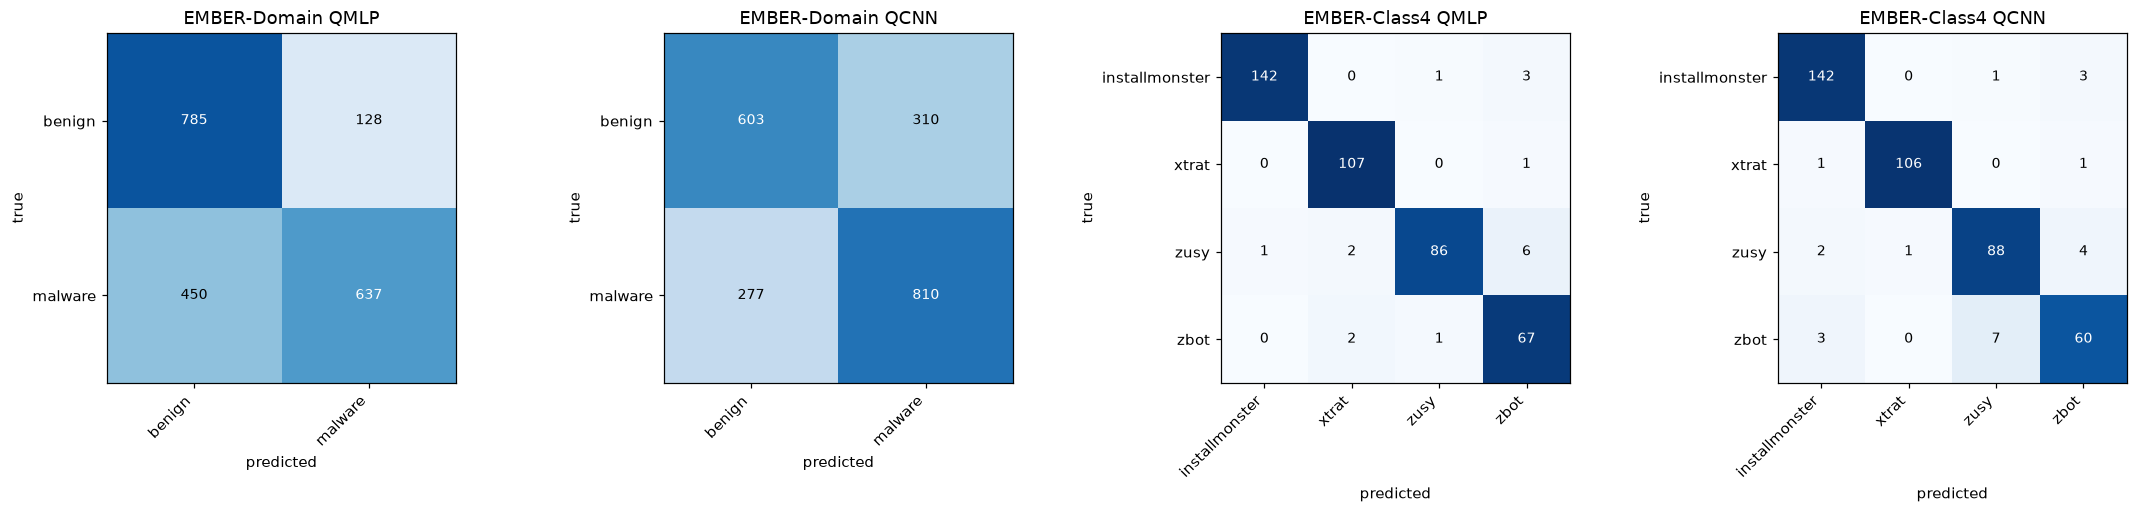

In [21]:
def plot_cm(ax, cm, classes, title):
    cmn = cm / cm.sum(1, keepdims=True).clip(1)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", color="white" if cmn[i, j] > 0.5 else "black", fontsize=9)
    ax.set_xticks(range(len(classes))); ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes, rotation=45, ha="right"); ax.set_yticklabels(classes)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title); ax.grid(False)
fig, ax = plt.subplots(1, 4, figsize=(20, 4.6))
for a, (nm, kind) in zip(ax, [("EMBER-Domain", "QMLP"), ("EMBER-Domain", "QCNN"), ("EMBER-Class4", "QMLP"), ("EMBER-Class4", "QCNN")]):
    t = TASKS0["domain" if nm == "EMBER-Domain" else "4"]
    plot_cm(a, CMS[(nm, kind)], t["classes"], f"{nm} {kind}")
plt.tight_layout(); plt.show()

## 7. Re-drawing the paper's results next to ours

The paper reports EMBER-Domain accuracy of about 77 % for both models and, on EMBER-Class, a clear separation between QMLP and QCNN as the number of families grows. The figure puts our numbers
(bars / lines, mean over seeds with the std as error bar) next to the paper's (black markers). **Read the gap with care:** we train on a few hundred to a thousand samples for a few epochs,
the paper on 90 000 to 220 000 samples for 20 epochs.

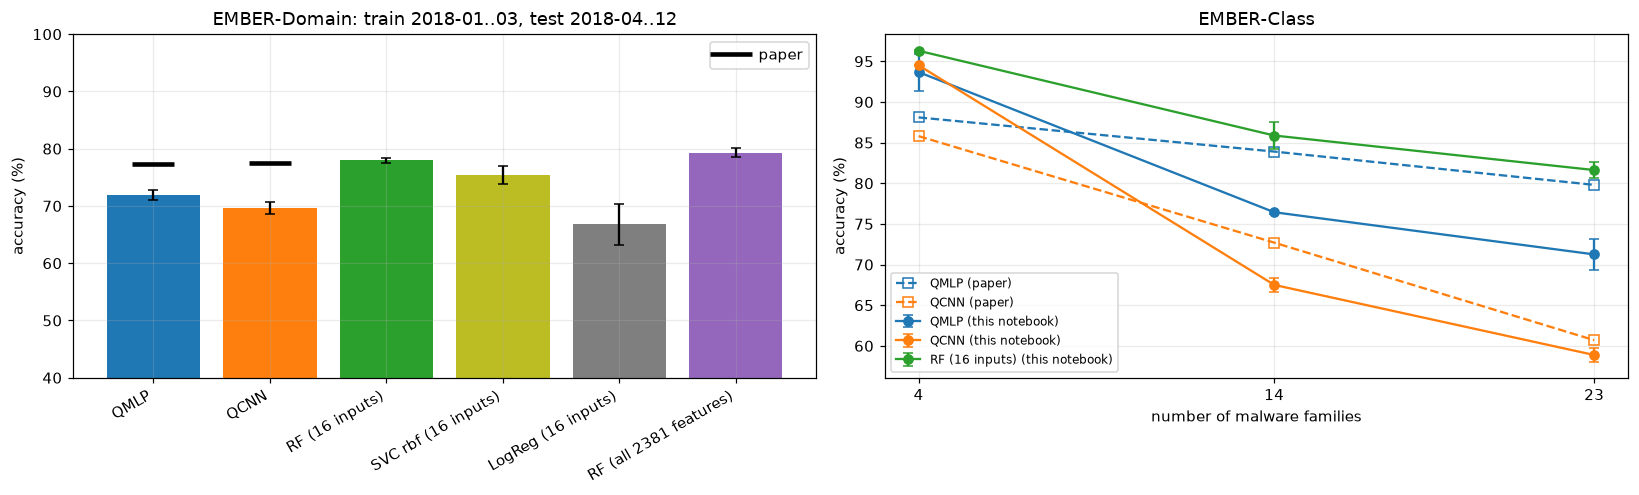

In [22]:
PAPER = {  # Tables I and II of the paper (percent): accuracy, precision, recall, F1, FPR, FNR, ROC-AUC
    ("EMBER-Domain", "QMLP"):  dict(acc=77.4, prec=77.3, rec=77.2, f1=77.3, fpr=22.8, fnr=23.0, auc=83.0),
    ("EMBER-Domain", "QCNN"):  dict(acc=77.5, prec=77.4, rec=77.3, f1=77.4, fpr=22.7, fnr=22.7, auc=84.1),
    ("EMBER-Class4", "QMLP"):  dict(acc=88.1, prec=86.1, rec=86.3, f1=86.2, fpr=3.8, fnr=13.7, auc=97.9),
    ("EMBER-Class14", "QMLP"): dict(acc=83.9, prec=82.9, rec=83.0, f1=83.0, fpr=1.3, fnr=17.0, auc=97.5),
    ("EMBER-Class23", "QMLP"): dict(acc=79.8, prec=76.2, rec=77.0, f1=76.6, fpr=0.9, fnr=23.0, auc=97.1),
    ("EMBER-Class4", "QCNN"):  dict(acc=85.8, prec=83.7, rec=83.7, f1=83.7, fpr=4.5, fnr=16.3, auc=97.1),
    ("EMBER-Class14", "QCNN"): dict(acc=72.7, prec=69.3, rec=67.5, f1=68.4, fpr=2.1, fnr=32.5, auc=94.0),
    ("EMBER-Class23", "QCNN"): dict(acc=60.7, prec=46.7, rec=49.7, f1=48.1, fpr=1.83, fnr=50.3, auc=92.5),
}
def ours(task, model, col="acc"):
    g = RES[(RES.task == task) & (RES.model == model)][col]
    return float(g.mean()), float(g.std(ddof=0))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
models = ["QMLP", "QCNN", "RF (16 inputs)", "SVC rbf (16 inputs)", "LogReg (16 inputs)", "RF (all 2381 features)"]
mu = [ours("EMBER-Domain", m)[0] for m in models]; sd = [ours("EMBER-Domain", m)[1] for m in models]
cols = ["tab:blue", "tab:orange", "tab:green", "tab:olive", "tab:gray", "tab:purple"]
ax[0].bar(range(len(models)), mu, yerr=sd, color=cols, capsize=3)
for i, m in enumerate(["QMLP", "QCNN"]):
    ax[0].plot([i], [PAPER[("EMBER-Domain", m)]["acc"]], "k_", ms=28, mew=3, label="paper" if i == 0 else None)
ax[0].set_xticks(range(len(models))); ax[0].set_xticklabels(models, rotation=30, ha="right"); ax[0].set_ylim(40, 100); ax[0].set_ylabel("accuracy (%)")
ax[0].set_title("EMBER-Domain: train 2018-01..03, test 2018-04..12"); ax[0].legend()
ks = CLASS_SIZES
for kind, col in (("QMLP", "tab:blue"), ("QCNN", "tab:orange"), ("RF (16 inputs)", "tab:green")):
    m_ = [ours(f"EMBER-Class{k}", kind)[0] for k in ks]; s_ = [ours(f"EMBER-Class{k}", kind)[1] for k in ks]
    ax[1].errorbar(ks, m_, yerr=s_, color=col, marker="o", label=f"{kind} (this notebook)", capsize=3)
    if kind in ("QMLP", "QCNN"):
        ax[1].plot(ks, [PAPER[(f"EMBER-Class{k}", kind)]["acc"] for k in ks], color=col, ls="--", marker="s", mfc="none", label=f"{kind} (paper)")
ax[1].set_xticks(ks); ax[1].set_xlabel("number of malware families"); ax[1].set_ylabel("accuracy (%)"); ax[1].set_title("EMBER-Class"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. Side-by-side comparison with the paper and a verdict per claim

Rule: a number is **reproduced** if it lies within 2 percentage points of the paper's value, **exceeded** if it is more than 2 points above, **not reached** if it is more than 2 points below.
Qualitative claims are judged from the numbers of this notebook. Claims about datasets that cannot be downloaded here are **cannot be checked**.

In [23]:
def verdict(o, p, tol=PAPER_TOL):
    d = o - p
    return "reproduced" if abs(d) <= tol else ("exceeded" if d > 0 else "not reached")

rows = []
for (task, model), pv in PAPER.items():
    for col, lab in (("acc", "accuracy"), ("f1", "F1"), ("auc", "ROC-AUC")):
        if task != "EMBER-Domain" and col == "auc":
            continue
        o = ours(task, model, col)[0]
        rows.append(dict(claim=f"{task} {model} {lab}", paper=pv[col], notebook=round(o, 1), diff=round(o - pv[col], 1), verdict=verdict(o, pv[col])))

# qualitative claims
acc = lambda t, m: ours(t, m)[0]
tq = lambda m: float(RES[RES.model == m].groupby("task").train_s.mean().mean())
q = [
    ("Binary: QMLP and QCNN reach the same accuracy (paper: 77.4 vs 77.5)", "|diff| <= 2",
     f"{acc('EMBER-Domain','QMLP'):.1f} vs {acc('EMBER-Domain','QCNN'):.1f}", abs(acc('EMBER-Domain','QMLP') - acc('EMBER-Domain','QCNN')) <= 2),
    ("QMLP beats QCNN with 14 families (paper: 83.9 vs 72.7)", "QMLP > QCNN",
     f"{acc('EMBER-Class14','QMLP'):.1f} vs {acc('EMBER-Class14','QCNN'):.1f}", acc('EMBER-Class14','QMLP') > acc('EMBER-Class14','QCNN')),
    ("QMLP beats QCNN with 23 families (paper: 79.8 vs 60.7)", "QMLP > QCNN",
     f"{acc('EMBER-Class23','QMLP'):.1f} vs {acc('EMBER-Class23','QCNN'):.1f}", acc('EMBER-Class23','QMLP') > acc('EMBER-Class23','QCNN')),
    ("QMLP accuracy falls as families grow 4 -> 14 -> 23 (paper: 88.1 > 83.9 > 79.8)", "monotone fall",
     " > ".join(f"{acc(f'EMBER-Class{k}','QMLP'):.1f}" for k in CLASS_SIZES), acc('EMBER-Class4','QMLP') > acc('EMBER-Class14','QMLP') > acc('EMBER-Class23','QMLP')),
    ("QCNN accuracy falls as families grow 4 -> 14 -> 23 (paper: 85.8 > 72.7 > 60.7)", "monotone fall",
     " > ".join(f"{acc(f'EMBER-Class{k}','QCNN'):.1f}" for k in CLASS_SIZES), acc('EMBER-Class4','QCNN') > acc('EMBER-Class14','QCNN') > acc('EMBER-Class23','QCNN')),
    ("QCNN trains faster than QMLP (fewer gates, 4 measured qubits)", "time(QCNN) < time(QMLP)",
     f"{tq('QCNN'):.0f} s vs {tq('QMLP'):.0f} s per run (simulator wall clock)", tq('QCNN') < tq('QMLP')),
]
for claim, rule, val, ok in q:
    rows.append(dict(claim=claim, paper=rule, notebook=val, diff="", verdict="reproduced" if ok else "not reproduced"))
for ds, txt in (("API-Graph binary / multiclass", "96.3 / 96.0 and 95.7 to 91.6"), ("AZ-Domain binary", "91.2 / 91.3"), ("AZ-Class multiclass", "QMLP 93.6 / 67.5 / 57.8; QCNN 92.1 / 55.3 / 41.7")):
    rows.append(dict(claim=ds, paper=txt, notebook="not run (data shared on request / needs an AndroZoo key)", diff="", verdict="cannot be checked"))
VERDICTS = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 120, "display.width", 200)
display(VERDICTS)
print(VERDICTS.verdict.value_counts().to_string())
print(f"\ntotal notebook run time: {(time.time()-T_NOTEBOOK)/60:.1f} min")

,claim,paper,notebook,diff,verdict
0,EMBER-Domain QMLP accuracy,77.4,71.9,-5.5,not reached
1,EMBER-Domain QMLP F1,77.3,71.8,-5.5,not reached
2,EMBER-Domain QMLP ROC-AUC,83.0,81.8,-1.2,reproduced
3,EMBER-Domain QCNN accuracy,77.5,69.7,-7.8,not reached
4,EMBER-Domain QCNN F1,77.4,69.3,-8.1,not reached
5,EMBER-Domain QCNN ROC-AUC,84.1,80.7,-3.4,not reached
6,EMBER-Class4 QMLP accuracy,88.1,93.7,5.6,exceeded
7,EMBER-Class4 QMLP F1,86.2,93.1,6.9,exceeded
8,EMBER-Class14 QMLP accuracy,83.9,76.4,-7.5,not reached
9,EMBER-Class14 QMLP F1,83.0,70.1,-12.9,not reached


verdict
not reached          12
reproduced            7
exceeded              4
cannot be checked     3
not reproduced        1

total notebook run time: 49.5 min


## 9. Reading the paper critically

* **What was actually tested.** Only the *relative* ordering of two small circuits is a quantum-specific claim. The paper never trains a classical model on the same 16 PCA inputs. Our random-forest, SVM and logistic-regression
  baselines on those very inputs show how much of the accuracy comes from the PCA compression and how much (if anything) from the quantum layer. Compare the QMLP/QCNN rows with the baselines above before drawing a quantum conclusion.
* **Binary EMBER-Domain is a drift test.** Training on January to March and testing on April to December means the evaluation files are newer than the training files. In the full run documented with this notebook (1 000 training samples, 12 epochs, 2 seeds) a random forest on the *same 16 PCA inputs* reaches about 78 % accuracy, i.e. the paper's 77 % is what a classical forest gets from those 16 inputs, while our QMLP / QCNN reach about 72 % / 70 % with this small training budget. The 16-component PCA projection, not the quantum layer, sets the accuracy ceiling (a forest on all 2 381 features gains only about 1 point more).
* **EMBER-Class with few families is easy.** Our top-4 pool has much larger families than the paper's (and a 70 / 30 split), so all models, quantum and classical, score above the paper's 88 % there; with 14 and 23 families the quantum models fall below the paper's numbers and below the classical baselines on identical inputs.
* **Precision of the numbers.** The standard deviations are over three repetitions of the same split; they do not describe sampling uncertainty of the test set, and the +- values for QMLP (2.5) versus QCNN (0.2) on EMBER-Domain
  mean the "equal accuracy" claim is not statistically settled.
* **API-Graph low macro-precision.** In the paper's Table I, API-Graph accuracy is 91.6 to 95.7 % while macro precision, recall and F1 are 4 to 30 %. That pattern means the models predict mostly one dominant class and most of the other
  families are never predicted correctly; accuracy alone is misleading for imbalanced families (macro-F1 is the honest number).
* **Training time claims.** "QCNN trains faster" is measured on a state-vector simulator; on a real device the number of two-qubit gates and shots matters, and the pooled-away qubits still have to be prepared and entangled.
* **Reproducibility gaps.** Learning rate, weight initialisation, the CRX wiring after pooling, how the multiclass train/test sets were drawn, and what exactly +- reports are not stated. The API-Graph and AZ feature files
  are not public, so three of the five datasets cannot be rerun by anyone without contacting the authors of those datasets.
* **Simulator exactness.** All results here are noise-free. Real devices with 16 qubits, a ring of 16 controlled gates and two repetitions of it would have depth in the hundreds of two-qubit layers once compiled to a device topology.

## 10. Exercises

1. **Data size.** Set `N_TRAIN_D` to 300, 1000 and 3000 (FAST_MODE=False) and plot QMLP accuracy against the number of training samples. Does it approach the random forest on the same 16 inputs?
2. **Angle encoding.** Compare `ANGLE_MODE = "paper"` and `"pi"` for the multiclass tasks (the notebook tunes only on the binary task). Which one is better at 14 families?
3. **Ablate data re-uploading.** Delete the second block of the QMLP program (`qmlp_program`) and retrain: how much accuracy does the re-uploading buy?
4. **Pooling.** Change the QCNN so that the first pooling keeps qubits 0 to 7 instead of the even ones. Does the accuracy change? Explain with the entanglement ring.
5. **Concept drift.** Train EMBER-Domain on 2018-01..03 and also on a random sample of 2018-04..12 (same size). How much accuracy does the temporal split cost, for the quantum models and for the random forest?